# Global Solution — Segurança Pública Inteligente em São Paulo
## Classificação de ocorrências como **roubo** ou **furto** com uma rede neural MLP

**Disciplina:** Aprendizado Profundo com Redes Neurais Convolucionais  
**Equipe:** Gabriel Guimarães de Oliveira - Rm567835
 Pedro Paulo Ferreira Agnelo D'angelo - Rm567564
 Mark Lima Leal - Rm566760
**Aplicação web:** https://spmobilecrimeclassifier.streamlit.app/  
**Repositório:** https://github.com/ZuziR6/sp-mobile-crime-classifier

> **O que o modelo faz — e o que não faz.** A MLP analisa as características de uma ocorrência **já registrada (ou hipotética)** e estima se ela é mais compatível com *roubo* ou com *furto*. Ela **não prevê** se, onde ou quando um crime vai acontecer, e as probabilidades que produz **não** representam o risco de crime em nenhum local ou horário.

### Resumo da solução

| Item | Descrição |
|---|---|
| Fonte | SSP-SP — Portal de Estatísticas, base *Celulares Subtraídos* 2025 (`CelularesSubtraidos_2025.xlsx`, aba `CELULAR_2025`) |
| Recorte | Fatos ocorridos no município de São Paulo (campo `CIDADE`) em 2025, com natureza *Furto (art. 155)* ou *Roubo (art. 157)* |
| Amostra final | 158.859 boletins de ocorrência (uma linha por boletim) |
| Variável-alvo | `0` = Furto (63,31%) · `1` = Roubo (36,69%) |
| Atributos | 6 variáveis categóricas (bairro, mês, dia da semana, período, tipo e subtipo de local) → 293 entradas após one-hot |
| Divisão | 70% treino · 15% validação · 15% teste (estratificada, `random_state=42`) |
| Arquiteturas | MLP_1_Compacta `[64, 32]` · MLP_2_Intermediaria `[128, 64, 32]` · MLP_3_Profunda `[256, 128, 64]` |
| Modelo escolhido | **MLP_1_Compacta** (critério: desempenho na validação e parcimônia) |
| Resultado no teste | Acurácia 83,19% · Precision (roubo) 75,87% · Recall (roubo) 79,47% · F1 (roubo) 77,63% · F1 macro 82,08% |

### Sumário
1. Ambiente e fonte dos dados
2. Exploração inicial da base
3. Recorte geográfico, temporal e definição do rótulo
4. Seleção dos atributos e consolidação por boletim
5. Divisão dos dados e pré-processamento
6. Implementação e treinamento das três MLPs
7. Curvas de treinamento e análise de overfitting/underfitting
8. Seleção da arquitetura (validação)
9. Experimentos complementares (limiar, pesos de classe, regularização)
10. Avaliação final no conjunto de teste
11. Exportação do modelo e aplicação web
12. Limitações e uso de IA generativa

### Como executar
1. Baixe a planilha em https://www.ssp.sp.gov.br/estatistica/consultas → **Bases de Dados** → **Celulares Subtraídos** → **2025** → *Download*.
2. Abra este notebook no Google Colab e execute **Runtime → Run all**. Na célula de upload, selecione o arquivo `CelularesSubtraidos_2025.xlsx` (≈ 103 MB). Fora do Colab, coloque o arquivo na mesma pasta do notebook.
3. Ao final, os artefatos da aplicação (`modelo_mlp.keras`, `preprocessor.joblib`, `configuracao.json`) e o `app.py` são gravados em `/content` (Colab).

---
## 1. Ambiente e fonte dos dados

In [ ]:
# ==========================================
# GLOBAL SOLUTION - SEGURANÇA PÚBLICA COM MLP
# ETAPA 1 - INSPEÇÃO DA BASE DE DADOS
# ==========================================

import pandas as pd
import numpy as np
import os
import warnings

warnings.filterwarnings("ignore")

print("Bibliotecas carregadas com sucesso!")
print("Versão do Pandas:", pd.__version__)
print("Versão do NumPy:", np.__version__)

Bibliotecas carregadas com sucesso!
Versão do Pandas: 2.2.3
Versão do NumPy: 2.4.6


In [ ]:
# ==========================================
# UPLOAD DA PLANILHA DA SSP-SP
# Fonte: https://www.ssp.sp.gov.br/estatistica/consultas
# Bases de Dados -> Celulares Subtraídos -> 2025 -> Download
# ==========================================
try:
    # Execução no Google Colab: seleciona o arquivo pela interface
    from google.colab import files

    print("Selecione a planilha baixada da SSP-SP:")
    uploaded = files.upload()
    arquivo = list(uploaded.keys())[0]
    tamanho_mb = len(uploaded[arquivo]) / 1024 / 1024

except ImportError:
    # Execução local: o arquivo deve estar na mesma pasta do notebook
    arquivo = "CelularesSubtraidos_2025.xlsx"
    tamanho_mb = os.path.getsize(arquivo) / 1024 / 1024

print("\nArquivo recebido:", arquivo)
print("Tamanho:", round(tamanho_mb, 2), "MB")

Selecione a planilha baixada da SSP-SP:


Saving CelularesSubtraidos_2025.xlsx to CelularesSubtraidos_2025.xlsx

Arquivo recebido: CelularesSubtraidos_2025.xlsx
Tamanho: 103.11 MB


---
## 2. Exploração inicial da base

Nesta etapa verificamos abas, colunas, tipos, valores ausentes, duplicatas, o dicionário de dados e a distribuição das principais variáveis. Dois pontos orientam as decisões seguintes:

- A coluna `RUBRICA` concentra, entre outras naturezas, **Furto (art. 155)** (169.628 registros) e **Roubo (art. 157)** (135.763), as duas classes do problema.
- Os campos de município têm significados diferentes, como mostra o dicionário da própria SSP-SP.

In [ ]:
# ==========================================
# IDENTIFICAÇÃO DA ESTRUTURA DO ARQUIVO
# ==========================================

extensao = os.path.splitext(arquivo)[1].lower()

if extensao in [".xlsx", ".xls"]:
    excel = pd.ExcelFile(arquivo)

    print("ABAS ENCONTRADAS:")
    print(excel.sheet_names)

    for aba in excel.sheet_names:
        dados_aba = pd.read_excel(arquivo, sheet_name=aba)

        print("\n" + "=" * 60)
        print("ABA:", aba)
        print("Linhas:", dados_aba.shape[0])
        print("Colunas:", dados_aba.shape[1])
        print("Colunas disponíveis:")
        print(dados_aba.columns.tolist())

    # Carrega a primeira aba para inspeção inicial
    df = pd.read_excel(arquivo, sheet_name=excel.sheet_names[0])

elif extensao == ".csv":
    try:
        df = pd.read_csv(arquivo, sep=None, engine="python")
    except UnicodeDecodeError:
        df = pd.read_csv(arquivo, sep=None, engine="python", encoding="latin1")

else:
    raise ValueError("Formato não suportado. Utilize Excel ou CSV.")

print("\nBASE CARREGADA COM SUCESSO!")
print("Dimensões:", df.shape)

ABAS ENCONTRADAS:
['METODOLOGIA', 'DICIONARIO DE DADOS', 'CELULAR_2025']

ABA: METODOLOGIA
Linhas: 12
Colunas: 1
Colunas disponíveis:
['Metodologia de extração e interpretação dos dados de ocorrências envolvendo subtração de celulares:']

ABA: DICIONARIO DE DADOS
Linhas: 58
Colunas: 2
Colunas disponíveis:
['A PRESENTE TABELA TEM POR FINALIDADE ESCLARECER OS CAMPOS CONTIDOS NA BASE DE DADOS', 'Unnamed: 1']

ABA: CELULAR_2025
Linhas: 383635
Colunas: 55
Colunas disponíveis:
['ID_DELEGACIA', 'NOME_DEPARTAMENTO', 'NOME_SECCIONAL', 'NOME_DELEGACIA', 'NOME_MUNICIPIO', 'ANO_BO', 'NUM_BO', 'VERSAO', 'NOME_DEPARTAMENTO_CIRC', 'NOME_SECCIONAL_CIRC', 'NOME_DELEGACIA_CIRC', 'NOME_MUNICIPIO_CIRC', 'DATA_OCORRENCIA_BO', 'HORA_OCORRENCIA', 'DESCRICAO_APRESENTACAO', 'DATAHORA_REGISTRO_BO', 'DATA_COMUNICACAO_BO', 'DATAHORA_IMPRESSAO_BO', 'DESCR_PERIODO', 'AUTORIA_BO', 'FLAG_INTOLERANCIA', 'TIPO_INTOLERANCIA', 'FLAG_FLAGRANTE', 'FLAG_STATUS', 'DESC_LEI', 'FLAG_ATO_INFRACIONAL', 'RUBRICA', 'DESCR_CONDUTA'

In [ ]:
# ==========================================
# DIAGNÓSTICO INICIAL DOS DADOS
# ==========================================

print("=" * 60)
print("1. DIMENSÕES DA BASE")
print("=" * 60)
print(df.shape)

print("\n2. TIPOS DE DADOS")
print(df.dtypes)

print("\n3. PRIMEIROS REGISTROS")
display(df.head(10))

print("\n4. VALORES AUSENTES")
ausentes = df.isnull().sum()
display(ausentes[ausentes > 0].sort_values(ascending=False))

print("\n5. REGISTROS DUPLICADOS")
print(df.duplicated().sum())

print("\n6. QUANTIDADE DE VALORES ÚNICOS")
display(df.nunique().sort_values(ascending=False))

print("\n7. INFORMAÇÕES GERAIS")
df.info()

1. DIMENSÕES DA BASE
(12, 1)

2. TIPOS DE DADOS
Metodologia de extração e interpretação dos dados de ocorrências envolvendo subtração de celulares:    object
dtype: object

3. PRIMEIROS REGISTROS


,Metodologia de extração e interpretação dos dados de ocorrências envolvendo subtração de celulares:
0,1. Origem dos Dados\nAs informações foram extr...
1,2. Dicionário de Dados\nPara facilitar a leitu...
2,3. Limitações e Qualidade dos Dados\nOs dados ...
3,4. Estrutura da Base de Dados\nCada linha da t...
4,NOME_DELEGACIA
5,ANO_BO
6,NUM_BO
7,5. Local de Registro x Local do Fato\nO cidadã...
8,6. Proteção de Dados Pessoais\nOs campos que p...
9,7. Recomendações para Uso dos Dados\nOs dados ...



4. VALORES AUSENTES


,0
Metodologia de extração e interpretação dos dados de ocorrências envolvendo subtração de celulares:,1



5. REGISTROS DUPLICADOS
0

6. QUANTIDADE DE VALORES ÚNICOS


,0
Metodologia de extração e interpretação dos dados de ocorrências envolvendo subtração de celulares:,11



7. INFORMAÇÕES GERAIS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 1 columns):
 #   Column                                                                                               Non-Null Count  Dtype 
---  ------                                                                                               --------------  ----- 
 0   Metodologia de extração e interpretação dos dados de ocorrências envolvendo subtração de celulares:  11 non-null     object
dtypes: object(1)
memory usage: 228.0+ bytes


In [ ]:
# ==========================================
# CARREGAMENTO DA BASE PRINCIPAL
# ==========================================

df = pd.read_excel(
    arquivo,
    sheet_name="CELULAR_2025"
)

print("BASE PRINCIPAL CARREGADA!")
print("=" * 60)

print("Quantidade de registros:", df.shape[0])
print("Quantidade de colunas:", df.shape[1])

print("\nPRIMEIROS 10 REGISTROS:")
display(df.head(10))

print("\nTIPOS DE DADOS:")
display(df.dtypes)

print("\nINFORMAÇÕES GERAIS:")
df.info()

BASE PRINCIPAL CARREGADA!
Quantidade de registros: 383635
Quantidade de colunas: 55

PRIMEIROS 10 REGISTROS:


,ID_DELEGACIA,NOME_DEPARTAMENTO,NOME_SECCIONAL,NOME_DELEGACIA,NOME_MUNICIPIO,ANO_BO,NUM_BO,VERSAO,NOME_DEPARTAMENTO_CIRC,NOME_SECCIONAL_CIRC,...,QUANTIDADE_OBJETO,MARCA_OBJETO,FLAG_BLOQUEIO,FLAG_DESBLOQUEIO,MES_REGISTRO_BO,ANO_REGISTRO_BO,CMD,BTL,CIA,CD_IBGE
0,900020,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA,S.PAULO,2025,AA1691,1,DECAP,DEL.SEC.1º CENTRO,...,1,Xiaomi,S,N,1,2025,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
1,900021,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA 1,S.PAULO,2025,AA2064,1,DECAP,DEL.SEC.1º CENTRO,...,1,Apple,S,N,1,2025,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
2,900020,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA,S.PAULO,2025,AA2458,1,DECAP,DEL.SEC.1º CENTRO,...,1,Motorola,S,N,1,2025,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
3,900020,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA,S.PAULO,2025,AA2520,1,DECAP,DEL.SEC.1º CENTRO,...,1,Samsung,S,N,1,2025,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
4,900020,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA,S.PAULO,2025,AA2537,1,DECAP,DEL.SEC.1º CENTRO,...,1,Apple,S,N,1,2025,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
5,900021,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA 1,S.PAULO,2025,AA2992,1,DECAP,DEL.SEC.1º CENTRO,...,1,Apple,S,N,1,2025,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
6,900020,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA,S.PAULO,2025,AA3794,1,DECAP,DEL.SEC.1º CENTRO,...,1,Samsung,S,N,1,2025,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
7,900020,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA,S.PAULO,2025,AA5440,1,DECAP,DEL.SEC.1º CENTRO,...,1,Motorola,N,N,1,2025,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
8,30424,DEMACRO,DEL.SEC.CARAPICUIBA,02º D.P. COTIA,S.PAULO,2025,AA8554,1,DECAP,DEL.SEC.1º CENTRO,...,1,Apple,N,N,1,2025,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
9,900021,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA 1,S.PAULO,2025,AA9147,1,DECAP,DEL.SEC.1º CENTRO,...,1,Samsung,S,N,1,2025,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308



TIPOS DE DADOS:


,0
ID_DELEGACIA,int64
NOME_DEPARTAMENTO,object
NOME_SECCIONAL,object
NOME_DELEGACIA,object
NOME_MUNICIPIO,object
ANO_BO,int64
NUM_BO,object
VERSAO,int64
NOME_DEPARTAMENTO_CIRC,object
NOME_SECCIONAL_CIRC,object



INFORMAÇÕES GERAIS:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 383635 entries, 0 to 383634
Data columns (total 55 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   ID_DELEGACIA            383635 non-null  int64         
 1   NOME_DEPARTAMENTO       383635 non-null  object        
 2   NOME_SECCIONAL          383635 non-null  object        
 3   NOME_DELEGACIA          383635 non-null  object        
 4   NOME_MUNICIPIO          383635 non-null  object        
 5   ANO_BO                  383635 non-null  int64         
 6   NUM_BO                  383635 non-null  object        
 7   VERSAO                  383635 non-null  int64         
 8   NOME_DEPARTAMENTO_CIRC  383635 non-null  object        
 9   NOME_SECCIONAL_CIRC     383635 non-null  object        
 10  NOME_DELEGACIA_CIRC     383635 non-null  object        
 11  NOME_MUNICIPIO_CIRC     383635 non-null  object        
 12  DATA_OCOR

In [ ]:
# ==========================================
# LEITURA DO DICIONÁRIO DE DADOS
# ==========================================

dicionario = pd.read_excel(
    arquivo,
    sheet_name="DICIONARIO DE DADOS",
    header=None
)

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)

print("DICIONÁRIO COMPLETO:")
display(dicionario)

print("\nDOCUMENTAÇÃO METODOLÓGICA:")

metodologia = pd.read_excel(
    arquivo,
    sheet_name="METODOLOGIA",
    header=None
)

for linha in metodologia.iloc[:, 0].dropna():
    print("\n", linha)

DICIONÁRIO COMPLETO:


,0,1
0,A PRESENTE TABELA TEM POR FINALIDADE ESCLARECER OS CAMPOS CONTIDOS NA BASE DE DADOS,NaN
1,*Resultado Null indica que o campo se encontrava vazio no banco de dados,NaN
2,NaN,NaN
3,Campos,Descrição
4,ANO_BO,Ano do boletim de ocorrência
5,ANO_REGISTRO_BO,Ano do registro da ocorrência
6,AUTORIA_BO,Autoria no boletim de ocorrência (C=conhecida; D=desconhecida)
7,BAIRRO,Bairro da ocorrência
8,CEP,Código de endereçamento postal
9,CIDADE,Cidade dos fatos



DOCUMENTAÇÃO METODOLÓGICA:

 Metodologia de extração e interpretação dos dados de ocorrências envolvendo subtração de celulares:

 1. Origem dos Dados
As informações foram extraídas dos sistemas Registro Digital de Ocorrências (R.D.O.) e Sistema de Polícia Judiciária (S.P.J.), utilizados para o registro de boletins de ocorrência nas delegacias de polícia do Estado de São Paulo.
O R.D.O. foi implantado gradualmente até alcançar todo o Estado em 2010, sendo substituído pelo S.P.J. entre 2022 e 2023.
Ambos os sistemas passam por atualizações contínuas para adequação às mudanças nas dinâmicas criminais e melhoria dos serviços prestados à população.

 2. Dicionário de Dados
Para facilitar a leitura e interpretação das variáveis, foi disponibilizada uma planilha denominada Dicionário de Dados, contendo a descrição de cada campo da base.

 3. Limitações e Qualidade dos Dados
Os dados referentes a celulares subtraídos foram disponibilizados em atendimento à demanda crescente por informações p

In [ ]:
# ==========================================
# INVESTIGAÇÃO DAS VARIÁVEIS PRINCIPAIS
# ==========================================

colunas_interesse = [
    "NOME_MUNICIPIO",
    "NOME_MUNICIPIO_CIRC",
    "RUBRICA",
    "DESCR_CONDUTA",
    "DESDOBRAMENTO",
    "CIRCUNSTANCIA",
    "DESCR_TIPOLOCAL",
    "DESCR_SUBTIPOLOCAL",
    "DESCR_PERIODO",
    "DATA_OCORRENCIA_BO",
    "HORA_OCORRENCIA",
    "BAIRRO",
    "DESCR_TIPO_OBJETO"
]

for coluna in colunas_interesse:

    if coluna in df.columns:

        print("\n" + "=" * 60)
        print("COLUNA:", coluna)
        print("Valores distintos:", df[coluna].nunique())
        print("Valores ausentes:", df[coluna].isna().sum())

        print("\n10 valores mais frequentes:")

        display(
            df[coluna]
            .value_counts(dropna=False)
            .head(10)
        )


COLUNA: NOME_MUNICIPIO
Valores distintos: 621
Valores ausentes: 0

10 valores mais frequentes:


,count
NOME_MUNICIPIO,
S.PAULO,216129
GUARULHOS,10821
CAMPINAS,9380
S.ANDRE,7720
S.BERNARDO DO CAMPO,6659
OSASCO,6612
PRAIA GRANDE,4100
RIBEIRAO PRETO,3996
S.VICENTE,3813



COLUNA: NOME_MUNICIPIO_CIRC
Valores distintos: 617
Valores ausentes: 0

10 valores mais frequentes:


,count
NOME_MUNICIPIO_CIRC,
S.PAULO,216287
GUARULHOS,10847
CAMPINAS,9375
S.ANDRE,7710
S.BERNARDO DO CAMPO,6674
OSASCO,6587
PRAIA GRANDE,4088
RIBEIRAO PRETO,3996
S.VICENTE,3817



COLUNA: RUBRICA
Valores distintos: 136
Valores ausentes: 0

10 valores mais frequentes:


,count
RUBRICA,
Furto (art. 155),169628
Roubo (art. 157),135763
Perda/Extravio,52074
Localização/Apreensão e Entrega de veículo,6486
Outros não criminal,1993
Estelionato (art. 171),1928
Localização/Apreensão de veículo,1650
Lesão corporal (art. 129),1536
Extorsão (art. 158),1156


... (16 outputs left out)


COLUNA: BAIRRO
Valores distintos: 14861
Valores ausentes: 3677

10 valores mais frequentes:


,count
BAIRRO,
CENTRO,22677
PINHEIROS,7031
BELA VISTA,5584
VILA MARIANA,4421
BOM RETIRO,4013
BARRA FUNDA,4009
SANTO AMARO,3968
REPUBLICA,3817
NaN,3677



COLUNA: DESCR_TIPO_OBJETO
Valores distintos: 1
Valores ausentes: 0

10 valores mais frequentes:


,count
DESCR_TIPO_OBJETO,
Telecomunicação,383635


---
## 3. Recorte geográfico, temporal e definição do rótulo

### 3.1 Qual campo indica o local do fato?

O enunciado pede para não confundir o **local do fato** com o **local de registro** do boletim. Segundo o dicionário de dados:

| Campo | Significado |
|---|---|
| `NOME_MUNICIPIO` | Município **responsável pelo registro** |
| `NOME_MUNICIPIO_CIRC` | Município da delegacia de **circunscrição** (onde ocorreu o fato) |
| `CIDADE` | **Cidade dos fatos** |

Usamos `CIDADE == "S.PAULO"` como critério do recorte, por ser o campo que descreve diretamente a cidade do fato. A auditoria abaixo mostra que 325 registros têm circunscrição em São Paulo, mas `CIDADE` em outros municípios (por exemplo, Itapecerica da Serra, Osasco e Diadema); esses ficam de fora do recorte.

### 3.2 Boletins repetidos

Um mesmo boletim (identificado por `NOME_DELEGACIA` + `ANO_BO` + `NUM_BO`) pode aparecer em **várias linhas**, por exemplo uma por objeto subtraído. Na auditoria inicial (roubo e furto com circunscrição em São Paulo, antes do filtro de 2025), 183.937 linhas correspondem a apenas 161.713 boletins únicos. Para não contar o mesmo fato mais de uma vez (o que também poderia levar o mesmo boletim para treino e teste), **consolidamos uma linha por boletim**.

In [ ]:
# ============================================================
# ETAPA 1.5 - DIAGNÓSTICO GEOGRÁFICO E DAS OCORRÊNCIAS
# ============================================================

# 1. Definição das colunas de identificação do boletim

chaves_bo = [
    "NOME_DELEGACIA",
    "ANO_BO",
    "NUM_BO"
]

# 2. Verificação dos municípios dos fatos

print("=" * 65)
print("1. DISTRIBUIÇÃO DOS MUNICÍPIOS DE CIRCUNSCRIÇÃO")
print("=" * 65)

display(
    df["NOME_MUNICIPIO_CIRC"]
    .value_counts()
    .head(15)
)

# 3. Recorte geográfico inicial

df_sp = df[
    df["NOME_MUNICIPIO_CIRC"]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("S.PAULO")
].copy()

print("\nRegistros no recorte de São Paulo:", len(df_sp))

print("\nMunicípios registrados na coluna CIDADE:")
display(df_sp["CIDADE"].value_counts().head(15))

# 4. Identificação das classes

print("\n" + "=" * 65)
print("2. DISTRIBUIÇÃO DAS NATUREZAS EM SÃO PAULO")
print("=" * 65)

display(df_sp["RUBRICA"].value_counts().head(20))

# 5. Seleção das duas classes do problema

classes_validas = [
    "Furto (art. 155)",
    "Roubo (art. 157)"
]

df_classificacao = df_sp[
    df_sp["RUBRICA"].isin(classes_validas)
].copy()

print("\nRegistros de roubo e furto em São Paulo:",
      len(df_classificacao))

print("\nDistribuição das classes:")
display(df_classificacao["RUBRICA"].value_counts())

# 6. Análise de repetição dos boletins

print("\n" + "=" * 65)
print("3. ANÁLISE DE BOLETINS REPETIDOS")
print("=" * 65)

total_linhas = len(df_classificacao)

total_bo = df_classificacao[chaves_bo].drop_duplicates().shape[0]

print("Total de linhas:", total_linhas)
print("Boletins únicos:", total_bo)
print("Linhas excedentes em relação aos boletins únicos:",
      total_linhas - total_bo)

# 7. Verificação de boletins com múltiplas naturezas

naturezas_por_bo = (
    df_classificacao
    .groupby(chaves_bo)["RUBRICA"]
    .nunique()
)

print("\nDistribuição da quantidade de naturezas por boletim:")
display(naturezas_por_bo.value_counts().sort_index())

bo_multiplas_naturezas = naturezas_por_bo[
    naturezas_por_bo > 1
]

print("\nBoletins associados às duas classes:",
      len(bo_multiplas_naturezas))

# 8. Verificação de boletins com uma única classe

bo_classe_unica = naturezas_por_bo[
    naturezas_por_bo == 1
]

print("\nBoletins com uma única classe:",
      len(bo_classe_unica))

# 9. Quantidade de boletins únicos por classe

print("\nBoletins únicos por classe:")

bo_por_classe = (
    df_classificacao
    .groupby(chaves_bo)["RUBRICA"]
    .first()
    .value_counts()
)

display(bo_por_classe)

# 10. Verificação do período temporal

print("\n" + "=" * 65)
print("4. PERÍODO DOS REGISTROS")
print("=" * 65)

print("Data inicial:", df_sp["DATA_OCORRENCIA_BO"].min())
print("Data final:", df_sp["DATA_OCORRENCIA_BO"].max())

print("\nQuantidade de datas distintas:",
      df_sp["DATA_OCORRENCIA_BO"].nunique())

# 11. Verificação de valores ausentes nas possíveis entradas

possiveis_atributos = [
    "DATA_OCORRENCIA_BO",
    "HORA_OCORRENCIA",
    "DESCR_PERIODO",
    "DESCR_TIPOLOCAL",
    "DESCR_SUBTIPOLOCAL",
    "BAIRRO"
]

print("\n" + "=" * 65)
print("5. VALORES AUSENTES NOS ATRIBUTOS")
print("=" * 65)

display(
    df_classificacao[possiveis_atributos]
    .isnull()
    .sum()
)

print("\nDIAGNÓSTICO CONCLUÍDO!")

1. DISTRIBUIÇÃO DOS MUNICÍPIOS DE CIRCUNSCRIÇÃO


,count
NOME_MUNICIPIO_CIRC,
S.PAULO,216287
GUARULHOS,10847
CAMPINAS,9375
S.ANDRE,7710
S.BERNARDO DO CAMPO,6674
OSASCO,6587
PRAIA GRANDE,4088
RIBEIRAO PRETO,3996
S.VICENTE,3817



Registros no recorte de São Paulo: 216287

Municípios registrados na coluna CIDADE:


,count
CIDADE,
S.PAULO,215962
ITAPECERICA DA SERRA,84
OSASCO,54
S.CAETANO DO SUL,43
DIADEMA,33
GUARULHOS,29
TABOAO DA SERRA,13
MAUA,13
EMBU DAS ARTES,10



2. DISTRIBUIÇÃO DAS NATUREZAS EM SÃO PAULO


,count
RUBRICA,
Furto (art. 155),106449
Roubo (art. 157),77488
Perda/Extravio,22133
Localização/Apreensão e Entrega de veículo,2600
Estelionato (art. 171),1055
Outros não criminal,812
Localização/Apreensão de veículo,621
Extorsão (art. 158),581
Lesão corporal (art. 129),455


... (5 outputs left out)

,count
RUBRICA,
Furto (art. 155),102005
Roubo (art. 157),59708



4. PERÍODO DOS REGISTROS
Data inicial: 2005-11-25 00:00:00
Data final: 2025-12-31 00:00:00

Quantidade de datas distintas: 920

5. VALORES AUSENTES NOS ATRIBUTOS


,0
DATA_OCORRENCIA_BO,0
HORA_OCORRENCIA,85453
DESCR_PERIODO,98484
DESCR_TIPOLOCAL,0
DESCR_SUBTIPOLOCAL,0
BAIRRO,569



DIAGNÓSTICO CONCLUÍDO!


In [ ]:
# ============================================================
# ETAPA 1.6 - AUDITORIA DE CONSISTÊNCIA DOS DADOS
# ============================================================

# 1. DISTRIBUIÇÃO DO ANO DO BOLETIM

print("=" * 65)
print("1. DISTRIBUIÇÃO DO ANO DO BOLETIM")
print("=" * 65)

display(df_sp["ANO_BO"].value_counts().sort_index())

print("\nAno do registro do BO:")
display(df_sp["ANO_REGISTRO_BO"].value_counts().sort_index())

print("\nAno da ocorrência:")
anos_ocorrencia = (
    df_sp["DATA_OCORRENCIA_BO"]
    .dt.year
    .value_counts()
    .sort_index()
)

display(anos_ocorrencia)

# 2. COMPARAÇÃO DOS CAMPOS GEOGRÁFICOS

print("\n" + "=" * 65)
print("2. DIVERGÊNCIAS GEOGRÁFICAS")
print("=" * 65)

comparacao_geo = pd.crosstab(
    df_sp["CIDADE"],
    df_sp["NOME_MUNICIPIO_CIRC"]
)

display(comparacao_geo)

divergencias = df_sp[
    df_sp["CIDADE"].astype(str).str.strip().str.upper()
    != df_sp["NOME_MUNICIPIO_CIRC"].astype(str).str.strip().str.upper()
]

print("\nTotal de divergências:", len(divergencias))

display(
    divergencias[
        ["CIDADE", "NOME_MUNICIPIO_CIRC", "RUBRICA"]
    ].head(15)
)

# 3. CONSISTÊNCIA DOS ATRIBUTOS DENTRO DE CADA BOLETIM

print("\n" + "=" * 65)
print("3. CONSISTÊNCIA DOS BOLETINS")
print("=" * 65)

atributos_auditoria = [
    "DATA_OCORRENCIA_BO",
    "HORA_OCORRENCIA",
    "DESCR_PERIODO",
    "DESCR_TIPOLOCAL",
    "DESCR_SUBTIPOLOCAL",
    "BAIRRO",
    "CIDADE",
    "NOME_MUNICIPIO_CIRC"
]

variacao_bo = (
    df_classificacao
    .groupby(chaves_bo)[atributos_auditoria]
    .nunique(dropna=False)
)

print("Quantidade de boletins:", len(variacao_bo))

print("\nBoletins com variação por atributo:")

display(
    (variacao_bo > 1)
    .sum()
    .sort_values(ascending=False)
)

print("\nBoletins com pelo menos um atributo divergente:")

bo_inconsistentes = variacao_bo[
    (variacao_bo > 1).any(axis=1)
]

print(len(bo_inconsistentes))

# 4. DISTRIBUIÇÃO DA QUANTIDADE DE LINHAS POR BOLETIM

print("\n" + "=" * 65)
print("4. QUANTIDADE DE LINHAS POR BOLETIM")
print("=" * 65)

linhas_por_bo = (
    df_classificacao
    .groupby(chaves_bo)
    .size()
)

display(
    linhas_por_bo
    .value_counts()
    .sort_index()
    .head(20)
)

print("\nMaior quantidade de linhas em um único BO:",
      linhas_por_bo.max())

# 5. INSPEÇÃO DE ALGUNS BOLETINS INCONSISTENTES

print("\n" + "=" * 65)
print("5. EXEMPLOS DE BOLETINS INCONSISTENTES")
print("=" * 65)

if len(bo_inconsistentes) > 0:

    exemplos = bo_inconsistentes.head(3).index

    for identificador in exemplos:

        print("\nBOLETIM:", identificador)

        mascara = np.ones(len(df_classificacao), dtype=bool)

        for coluna, valor in zip(chaves_bo, identificador):
            mascara &= df_classificacao[coluna].eq(valor).to_numpy()

        display(
            df_classificacao.loc[
                mascara,
                chaves_bo + atributos_auditoria + ["RUBRICA"]
            ]
        )

print("\nAUDITORIA CONCLUÍDA!")

1. DISTRIBUIÇÃO DO ANO DO BOLETIM


,count
ANO_BO,
2024,9
2025,216278



Ano do registro do BO:


,count
ANO_REGISTRO_BO,
2025,216287



Ano da ocorrência:


,count
DATA_OCORRENCIA_BO,
2005,1
2006,4
2007,6
2008,1
2009,1
2011,1
2012,3
2014,7
2015,95


... (11 outputs left out)

,NOME_DELEGACIA,ANO_BO,NUM_BO,DATA_OCORRENCIA_BO,HORA_OCORRENCIA,DESCR_PERIODO,DESCR_TIPOLOCAL,DESCR_SUBTIPOLOCAL,BAIRRO,CIDADE,NOME_MUNICIPIO_CIRC,RUBRICA
72766,01º D.P. INDAIATUBA,2025,ES4177,2025-03-29,NaN,A noite,Via Pública,Via Pública,LAPA,S.PAULO,S.PAULO,Roubo (art. 157)
72767,01º D.P. INDAIATUBA,2025,ES4177,2025-03-29,NaN,A noite,Via Pública,Via Pública,LAPA,S.PAULO,S.PAULO,Roubo (art. 157)
77422,01º D.P. INDAIATUBA,2025,ES4177,2025-03-29,NaN,A noite,Via Pública,Via Pública,FREGUESIA DO O,S.PAULO,S.PAULO,Roubo (art. 157)
77423,01º D.P. INDAIATUBA,2025,ES4177,2025-03-29,NaN,A noite,Via Pública,Via Pública,FREGUESIA DO O,S.PAULO,S.PAULO,Roubo (art. 157)



BOLETIM: ('01º D.P. S.B.C-DR OMAR CASSIM', 2025, 'BL4396')


,NOME_DELEGACIA,ANO_BO,NUM_BO,DATA_OCORRENCIA_BO,HORA_OCORRENCIA,DESCR_PERIODO,DESCR_TIPOLOCAL,DESCR_SUBTIPOLOCAL,BAIRRO,CIDADE,NOME_MUNICIPIO_CIRC,RUBRICA
12574,01º D.P. S.B.C-DR OMAR CASSIM,2025,BL4396,2025-01-28,22:50:00,NaN,Via Pública,Via Pública,CHÁCARA GAIVOTAS,S.PAULO,S.PAULO,Roubo (art. 157)
14397,01º D.P. S.B.C-DR OMAR CASSIM,2025,BL4396,2025-01-28,22:50:00,NaN,Via Pública,Via Pública,PEDREIRA,DIADEMA,S.PAULO,Roubo (art. 157)



AUDITORIA CONCLUÍDA!


### 3.3 Regras de seleção e rótulo

| Etapa | Regra | Registros / boletins |
|---|---|---|
| Local do fato | `CIDADE == "S.PAULO"` e data da ocorrência em **2025** | 213.411 linhas |
| Natureza | `RUBRICA` ∈ {Furto (art. 155), Roubo (art. 157)} | 181.707 linhas (105.074 furtos e 76.633 roubos) |
| Ambiguidade | Remover boletins com **as duas naturezas** (roubo e furto) | −44 boletins → 181.566 linhas |
| Consistência | Remover boletins cujas linhas divergem em bairro, tipo ou subtipo de local | −820 boletins (0,51%) |
| Consolidação | Uma linha por boletim | **158.859 boletins** |

> A planilha de 2025 contém fatos com datas desde 2005 (boletins registrados em 2025 sobre fatos antigos). Por isso o filtro temporal usa a **data da ocorrência**, e não o ano do boletim.

**Rótulo (variável-alvo):** `0` = Furto (art. 155) e `1` = Roubo (art. 157). A coluna `RUBRICA`, que define o alvo, **não entra** nas variáveis de entrada.

In [ ]:
# ============================================================
# ETAPA 1.7 - DEFINIÇÃO DO RECORTE GEOGRÁFICO E TEMPORAL
# ============================================================

# 1. FILTRO DO LOCAL EFETIVO DA OCORRÊNCIA

df_recorte = df[
    df["CIDADE"]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("S.PAULO")
].copy()

# 2. FILTRO DO ANO DA OCORRÊNCIA

df_recorte = df_recorte[
    df_recorte["DATA_OCORRENCIA_BO"].dt.year == 2025
].copy()

print("=" * 65)
print("1. RECORTE GEOGRÁFICO E TEMPORAL")
print("=" * 65)

print("Registros após os filtros:", len(df_recorte))

print("\nDistribuição das cidades:")
display(df_recorte["CIDADE"].value_counts())

print("\nDistribuição das datas por mês:")
display(
    df_recorte["DATA_OCORRENCIA_BO"]
    .dt.month
    .value_counts()
    .sort_index()
)

# 3. SELEÇÃO DE ROUBOS E FURTOS

classes_validas = [
    "Furto (art. 155)",
    "Roubo (art. 157)"
]

df_alvo = df_recorte[
    df_recorte["RUBRICA"].isin(classes_validas)
].copy()

print("\n" + "=" * 65)
print("2. DISTRIBUIÇÃO DAS CLASSES")
print("=" * 65)

print("Total de registros:", len(df_alvo))

display(df_alvo["RUBRICA"].value_counts())

# 4. IDENTIFICAÇÃO DOS BOLETINS

chaves_bo = [
    "NOME_DELEGACIA",
    "ANO_BO",
    "NUM_BO"
]

naturezas_por_bo = (
    df_alvo
    .groupby(chaves_bo)["RUBRICA"]
    .nunique()
)

bo_ambiguos = naturezas_por_bo[
    naturezas_por_bo > 1
].index

print("\n" + "=" * 65)
print("3. BOLETINS COM MAIS DE UMA CLASSE")
print("=" * 65)

print("Boletins com classificação ambígua:", len(bo_ambiguos))

# Exclui boletins associados simultaneamente a roubo e furto
df_sem_ambiguos = (
    df_alvo
    .set_index(chaves_bo)
    .drop(index=bo_ambiguos)
    .reset_index()
)

print("Registros após exclusão:", len(df_sem_ambiguos))

# 5. AUDITORIA DE CONSISTÊNCIA DOS ATRIBUTOS

atributos_auditoria = [
    "DATA_OCORRENCIA_BO",
    "HORA_OCORRENCIA",
    "DESCR_PERIODO",
    "DESCR_TIPOLOCAL",
    "DESCR_SUBTIPOLOCAL",
    "BAIRRO",
    "CIDADE"
]

variacao_bo = (
    df_sem_ambiguos
    .groupby(chaves_bo)[atributos_auditoria]
    .nunique(dropna=False)
)

bo_inconsistentes = variacao_bo[
    (variacao_bo > 1).any(axis=1)
]

print("\n" + "=" * 65)
print("4. CONSISTÊNCIA DOS BOLETINS")
print("=" * 65)

print("Boletins únicos:", len(variacao_bo))
print("Boletins inconsistentes:", len(bo_inconsistentes))
print(
    "Percentual de boletins inconsistentes:",
    round(len(bo_inconsistentes) / len(variacao_bo) * 100, 2),
    "%"
)

print("\nVariações por atributo:")
display(
    (variacao_bo > 1)
    .sum()
    .sort_values(ascending=False)
)

# 6. DISTRIBUIÇÃO DAS CLASSES POR BOLETIM NÃO AMBÍGUO

print("\n" + "=" * 65)
print("5. DISTRIBUIÇÃO POR BOLETIM")
print("=" * 65)

bo_por_classe = (
    df_sem_ambiguos
    .groupby(chaves_bo)["RUBRICA"]
    .first()
    .value_counts()
)

display(bo_por_classe)

print("\nETAPA 1.7 CONCLUÍDA!")

1. RECORTE GEOGRÁFICO E TEMPORAL
Registros após os filtros: 213411

Distribuição das cidades:


,count
CIDADE,
S.PAULO,213411



Distribuição das datas por mês:


,count
DATA_OCORRENCIA_BO,
1,17110
2,17789
3,19896
4,17513
5,18652
6,17424
7,18200
8,18687
9,18401



2. DISTRIBUIÇÃO DAS CLASSES
Total de registros: 181707


,count
RUBRICA,
Furto (art. 155),105074
Roubo (art. 157),76633



3. BOLETINS COM MAIS DE UMA CLASSE
Boletins com classificação ambígua: 44
Registros após exclusão: 181566

4. CONSISTÊNCIA DOS BOLETINS
Boletins únicos: 159679
Boletins inconsistentes: 820
Percentual de boletins inconsistentes: 0.51 %

Variações por atributo:


,0
BAIRRO,761
DESCR_SUBTIPOLOCAL,292
DESCR_TIPOLOCAL,239
DESCR_PERIODO,0
HORA_OCORRENCIA,0
DATA_OCORRENCIA_BO,0
CIDADE,0



5. DISTRIBUIÇÃO POR BOLETIM


,count
RUBRICA,
Furto (art. 155),100701
Roubo (art. 157),58978



ETAPA 1.7 CONCLUÍDA!


---
## 4. Seleção dos atributos e consolidação por boletim

### 4.1 Atributos de entrada e justificativa

| Atributo | Origem | Categorias | Por que usar |
|---|---|---|---|
| `BAIRRO` | `BAIRRO` | 1.821 distintas (as raras, com menos de 50 ocorrências, são agrupadas) | O perfil urbano muda por região (centro, terminais, áreas residenciais) |
| `MES` | mês de `DATA_OCORRENCIA_BO` | 12 | Possível sazonalidade |
| `DIA_SEMANA` | dia da semana de `DATA_OCORRENCIA_BO` | 7 | A dinâmica do dia útil difere da do fim de semana |
| `DESCR_PERIODO` | `DESCR_PERIODO` | 6 | Período do dia (manhã, tarde, noite, madrugada) |
| `DESCR_TIPOLOCAL` | `DESCR_TIPOLOCAL` | 28 | Via pública, terminal, residência, comércio etc. |
| `DESCR_SUBTIPOLOCAL` | `DESCR_SUBTIPOLOCAL` | 197 | Detalha o tipo de local (por exemplo, transeunte, interior de ônibus) |

`MES` e `DIA_SEMANA` são tratados como **categorias** (e não como números), porque a relação com o alvo não é monotônica.

### 4.2 O que ficou de fora e por quê

- **`RUBRICA`**: é o próprio alvo (evita *data leakage*).
- **Campos que descrevem a dinâmica do fato** (`DESCR_CONDUTA`, `DESDOBRAMENTO`, `CIRCUNSTANCIA`): estão ligados à natureza jurídica e poderiam revelar indiretamente a classe.
- **Identificação e endereço exato** (`NUM_BO`, `LOGRADOURO`, `NUMERO_LOGRADOURO`, `CEP`, latitude e longitude): identificadores ou dados que apontam para pessoas ou endereços específicos.
- **`HORA_OCORRENCIA`**: tem 85.453 ausências no recorte inicial e é coberta, em termos de informação, pelo `DESCR_PERIODO`.
- Atributos do objeto (`DESCR_TIPO_OBJETO`, marca etc.): a base é toda de celulares, então pouco discriminam.

### 4.3 Tratamento de ausentes e consolidação

Ausências nas categorias viram a categoria explícita `NAO_INFORMADO`. Isso é relevante em `DESCR_PERIODO`: **77.263 boletins (≈ 48,6%)** não informam o período, e o modelo trata essa informação como mais uma categoria.

In [ ]:
# ============================================================
# ETAPA 1.8 - LIMPEZA E CONSOLIDAÇÃO DOS BOLETINS
# ============================================================

# 1. REMOVER BOLETINS COM ATRIBUTOS INCONSISTENTES

df_consistente = (
    df_sem_ambiguos
    .set_index(chaves_bo)
    .drop(index=bo_inconsistentes.index)
    .reset_index()
)

print("=" * 65)
print("1. REMOÇÃO DOS BOLETINS INCONSISTENTES")
print("=" * 65)

print("Registros antes:", len(df_sem_ambiguos))
print("Registros depois:", len(df_consistente))
print("Boletins inconsistentes removidos:", len(bo_inconsistentes))

# 2. CONSOLIDAR UMA LINHA POR BOLETIM

df_boletins = (
    df_consistente
    .drop_duplicates(subset=chaves_bo)
    .copy()
)

print("\n" + "=" * 65)
print("2. CONSOLIDAÇÃO DOS BOLETINS")
print("=" * 65)

print("Linhas após deduplicação:", len(df_boletins))
print("Identificadores únicos:",
      df_boletins[chaves_bo].drop_duplicates().shape[0])

# 3. CRIAR A VARIÁVEL-ALVO BINÁRIA

df_boletins["target"] = (
    df_boletins["RUBRICA"]
    .map({
        "Furto (art. 155)": 0,
        "Roubo (art. 157)": 1
    })
)

print("\n" + "=" * 65)
print("3. DISTRIBUIÇÃO DA VARIÁVEL-ALVO")
print("=" * 65)

display(
    df_boletins["target"]
    .value_counts()
    .rename(index={
        0: "Furto",
        1: "Roubo"
    })
)

# 4. ENGENHARIA DE ATRIBUTOS TEMPORAIS

df_boletins["MES"] = (
    df_boletins["DATA_OCORRENCIA_BO"]
    .dt.month
    .astype(str)
)

df_boletins["DIA_SEMANA"] = (
    df_boletins["DATA_OCORRENCIA_BO"]
    .dt.dayofweek
    .astype(str)
)

# 5. DEFINIR AS VARIÁVEIS PREDITIVAS

colunas_features = [
    "BAIRRO",
    "MES",
    "DIA_SEMANA",
    "DESCR_PERIODO",
    "DESCR_TIPOLOCAL",
    "DESCR_SUBTIPOLOCAL"
]

df_modelo = df_boletins[
    colunas_features + ["target"]
].copy()

# 6. TRATAR VALORES AUSENTES DAS CATEGORIAS

for coluna in colunas_features:
    df_modelo[coluna] = (
        df_modelo[coluna]
        .fillna("NAO_INFORMADO")
        .astype(str)
        .str.strip()
    )

# 7. VERIFICAR A QUALIDADE DO DATASET

print("\n" + "=" * 65)
print("4. DATASET FINAL - DIAGNÓSTICO")
print("=" * 65)

print("Quantidade de registros:", len(df_modelo))
print("Quantidade de atributos:", len(colunas_features))
print("Valores ausentes:")
display(df_modelo.isnull().sum())

print("\nDistribuição das classes:")
display(df_modelo["target"].value_counts())

print("\nProporção das classes (%):")
display(
    (df_modelo["target"].value_counts(normalize=True) * 100)
    .round(2)
)

# 8. CARDINALIDADE DAS VARIÁVEIS CATEGÓRICAS

print("\n" + "=" * 65)
print("5. CARDINALIDADE DOS ATRIBUTOS")
print("=" * 65)

for coluna in colunas_features:

    print(f"\n{coluna}")
    print("Categorias distintas:", df_modelo[coluna].nunique())

    display(
        df_modelo[coluna]
        .value_counts()
        .head(10)
    )

# 9. VERIFICAÇÕES FINAIS

print("\n" + "=" * 65)
print("6. VERIFICAÇÕES FINAIS")
print("=" * 65)

print(
    "Boletins duplicados:",
    df_boletins.duplicated(subset=chaves_bo).sum()
)

print(
    "Classes não identificadas:",
    df_boletins["target"].isnull().sum()
)

print(
    "Datas fora de 2025:",
    (df_boletins["DATA_OCORRENCIA_BO"].dt.year != 2025).sum()
)

print(
    "Cidades diferentes de São Paulo:",
    (
        df_boletins["CIDADE"]
        .astype(str)
        .str.strip()
        .str.upper()
        != "S.PAULO"
    ).sum()
)

print("\nETAPA 1.8 CONCLUÍDA!")

1. REMOÇÃO DOS BOLETINS INCONSISTENTES
Registros antes: 181566
Registros depois: 177571
Boletins inconsistentes removidos: 820

2. CONSOLIDAÇÃO DOS BOLETINS
Linhas após deduplicação: 158859
Identificadores únicos: 158859

3. DISTRIBUIÇÃO DA VARIÁVEL-ALVO


,count
target,
Furto,100571
Roubo,58288



4. DATASET FINAL - DIAGNÓSTICO
Quantidade de registros: 158859
Quantidade de atributos: 6
Valores ausentes:


,0
BAIRRO,0
MES,0
DIA_SEMANA,0
DESCR_PERIODO,0
DESCR_TIPOLOCAL,0
DESCR_SUBTIPOLOCAL,0
target,0



Distribuição das classes:


,count
target,
0,100571
1,58288


... (11 outputs left out)

,count
DESCR_TIPOLOCAL,
Via Pública,124206
Terminal/Estação,16551
Outros,11949
Residência,1245
Estacionamento/Garagem,904
Comércio e Serviços,676
Rodovia/Estrada,567
Lazer e Recreação,545
Restaurante e Afins,530



DESCR_SUBTIPOLOCAL
Categorias distintas: 197


,count
DESCR_SUBTIPOLOCAL,
Via Pública,120233
Metroviário e Ferroviário Metropolitano,15380
Outros,12016
Transeunte,1351
Interior de Transporte Coletivo,1299
Casa,1112
Veículo em movimento,866
Ônibus/Lotação/Trolebus,811
Interior de Veículo Particular,516



6. VERIFICAÇÕES FINAIS
Boletins duplicados: 0
Classes não identificadas: 0
Datas fora de 2025: 0
Cidades diferentes de São Paulo: 0

ETAPA 1.8 CONCLUÍDA!


---
## 5. Divisão dos dados e pré-processamento

- **Divisão estratificada 70/15/15** (`random_state=42`): treino 111.201, validação 23.829 e teste 23.829 boletins. A proporção de classes (63,31% furto / 36,69% roubo) é preservada nos três conjuntos.
- **Codificação:** `OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50)`. Categorias com menos de 50 ocorrências no treino são agrupadas em uma coluna "infrequente", o que reduz ruído e dá um destino seguro a categorias novas na hora da inferência. Resultado: **293 entradas**.
- **Sem vazamento:** o codificador é ajustado **somente com o treino** (`fit_transform`) e apenas aplicado (`transform`) em validação e teste.
- **Escalonamento:** não é necessário. Todas as entradas são variáveis binárias (0/1), que já estão na mesma escala.

In [ ]:
# ============================================================
# ETAPA 1.9 - DIVISÃO DOS DADOS E PRÉ-PROCESSAMENTO
# ============================================================

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

print("Versão do Scikit-learn:", sklearn.__version__)

# 1. SEPARAR ATRIBUTOS E VARIÁVEL-ALVO

X = df_modelo[colunas_features].copy()
y = df_modelo["target"].astype("int8").copy()

# 2. PRIMEIRA DIVISÃO: 70% TREINO / 30% TEMPORÁRIO

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# 3. SEGUNDA DIVISÃO: 15% VALIDAÇÃO / 15% TESTE

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("\n" + "=" * 65)
print("1. DIMENSÕES DOS CONJUNTOS")
print("=" * 65)

print("Treinamento:", X_train.shape)
print("Validação:", X_val.shape)
print("Teste:", X_test.shape)

# 4. VERIFICAR PROPORÇÃO DAS CLASSES

print("\n" + "=" * 65)
print("2. DISTRIBUIÇÃO DAS CLASSES")
print("=" * 65)

for nome, conjunto in [
    ("Treinamento", y_train),
    ("Validação", y_val),
    ("Teste", y_test)
]:

    print(f"\n{nome}:")

    display(
        (
            conjunto
            .value_counts(normalize=True)
            .sort_index() * 100
        ).round(2)
    )

# 5. CONFIGURAR ONE-HOT ENCODING

try:

    encoder = OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency=50,
        sparse_output=False,
        dtype=np.float32
    )

except TypeError:

    # Compatibilidade com versões antigas do Scikit-learn

    encoder = OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency=50,
        sparse=False,
        dtype=np.float32
    )

# 6. CRIAR O PRÉ-PROCESSADOR

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            encoder,
            colunas_features
        )
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

# 7. AJUSTAR SOMENTE COM OS DADOS DE TREINAMENTO

X_train_proc = preprocessor.fit_transform(X_train)

# Transformar validação e teste sem reajustar o codificador

X_val_proc = preprocessor.transform(X_val)

X_test_proc = preprocessor.transform(X_test)

# 8. GARANTIR FORMATO NUMÉRICO FLOAT32

X_train_proc = np.asarray(
    X_train_proc,
    dtype=np.float32
)

X_val_proc = np.asarray(
    X_val_proc,
    dtype=np.float32
)

X_test_proc = np.asarray(
    X_test_proc,
    dtype=np.float32
)

# 9. VERIFICAR DIMENSÕES APÓS CODIFICAÇÃO

print("\n" + "=" * 65)
print("3. DIMENSÕES APÓS ONE-HOT ENCODING")
print("=" * 65)

print("Treinamento:", X_train_proc.shape)
print("Validação:", X_val_proc.shape)
print("Teste:", X_test_proc.shape)

print(
    "\nQuantidade de entradas da futura MLP:",
    X_train_proc.shape[1]
)

# 10. VERIFICAR NOMES DAS FEATURES GERADAS

nomes_features = preprocessor.get_feature_names_out()

print("\nQuantidade de features geradas:", len(nomes_features))

print("\nExemplos das features:")
display(pd.DataFrame({
    "feature": nomes_features[:30]
}))

# 11. VERIFICAÇÕES FINAIS

print("\n" + "=" * 65)
print("4. VERIFICAÇÕES FINAIS")
print("=" * 65)

print("Valores ausentes no treino:",
      np.isnan(X_train_proc).sum())

print("Valores ausentes na validação:",
      np.isnan(X_val_proc).sum())

print("Valores ausentes no teste:",
      np.isnan(X_test_proc).sum())

print("Valores infinitos no treino:",
      np.isinf(X_train_proc).sum())

print("\nETAPA 1.9 CONCLUÍDA!")

Versão do Scikit-learn: 1.6.1

1. DIMENSÕES DOS CONJUNTOS
Treinamento: (111201, 6)
Validação: (23829, 6)
Teste: (23829, 6)

2. DISTRIBUIÇÃO DAS CLASSES

Treinamento:


,proportion
target,
0,63.31
1,36.69



Validação:


,proportion
target,
0,63.31
1,36.69



Teste:


,proportion
target,
0,63.31
1,36.69



3. DIMENSÕES APÓS ONE-HOT ENCODING
Treinamento: (111201, 293)
Validação: (23829, 293)
Teste: (23829, 293)

Quantidade de entradas da futura MLP: 293

Quantidade de features geradas: 293

Exemplos das features:


,feature
0,BAIRRO_AGUA RASA
1,BAIRRO_ALTO DE PINHEIROS
2,BAIRRO_AMERICANÓPOLIS
3,BAIRRO_ANHANGUERA
4,BAIRRO_ARICANDUVA
5,BAIRRO_ARTUR ALVIM
6,BAIRRO_BARRA FUNDA
7,BAIRRO_BELA VISTA
8,BAIRRO_BELEM
9,BAIRRO_BELENZINHO



4. VERIFICAÇÕES FINAIS
Valores ausentes no treino: 0
Valores ausentes na validação: 0
Valores ausentes no teste: 0
Valores infinitos no treino: 0

ETAPA 1.9 CONCLUÍDA!


---
## 6. Implementação e treinamento das três MLPs

### 6.1 Estrutura comum

```
Entrada (293) → [Dense(n, ReLU, L2=1e-4) → Dropout(0,20)] × k → Dense(1, sigmoid)
```

| Componente | Escolha | Justificativa |
|---|---|---|
| Ativação oculta | ReLU | Simples, rápida e evita o desaparecimento de gradiente em redes rasas |
| Saída | 1 neurônio, **sigmoid** | Classificação binária: a saída é a probabilidade de **roubo** |
| Perda | *Binary crossentropy* | Perda natural para saída sigmoide e rótulos 0/1 |
| Otimizador | Adam, taxa inicial 1e-3 | Converge bem sem ajuste fino de taxa |
| Regularização | Dropout 0,20 e L2 1e-4 | Reduz o overfitting, esperado com 293 entradas esparsas |
| Batch size | 256 | Equilíbrio entre estabilidade e tempo de treino (435 passos por época) |
| Épocas | até 50 | Limitadas por *early stopping* |
| Callbacks | `EarlyStopping` (`val_loss`, paciência 7, restaura melhores pesos) e `ReduceLROnPlateau` (fator 0,5, paciência 3) | Interrompe antes do overfitting e refina a taxa de aprendizado |

### 6.2 Arquiteturas comparadas

Para isolar o efeito da **capacidade** do modelo, variamos apenas a quantidade de camadas e neurônios. Todo o resto (ativação, perda, otimizador, regularização e batch) é mantido.

| Modelo | Camadas ocultas | Parâmetros treináveis | Motivação |
|---|---|---|---|
| `MLP_1_Compacta` | 64 → 32 | 20.929 | Linha de base simples |
| `MLP_2_Intermediaria` | 128 → 64 → 32 | 48.001 | Mais profundidade e largura |
| `MLP_3_Profunda` | 256 → 128 → 64 | 116.481 | Maior capacidade, para testar se mais parâmetros ajudam |

A seleção é feita **somente na validação**; o conjunto de teste fica reservado para a avaliação final.

In [ ]:
# ============================================================
# ETAPA 2.1 - CONSTRUÇÃO E TREINAMENTO DAS TRÊS MLPs
# ============================================================

import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. CONFIGURAÇÕES GERAIS

tf.keras.utils.set_random_seed(42)

entrada = X_train_proc.shape[1]

print("Entradas da rede:", entrada)

# 2. DEFINIÇÃO DAS ARQUITETURAS

arquiteturas = {
    "MLP_1_Compacta": [64, 32],
    "MLP_2_Intermediaria": [128, 64, 32],
    "MLP_3_Profunda": [256, 128, 64]
}

# 3. FUNÇÃO PARA CONSTRUIR A REDE

def construir_mlp(neuronios, nome):

    modelo = tf.keras.Sequential(name=nome)

    modelo.add(
        tf.keras.layers.Input(shape=(entrada,))
    )

    for quantidade in neuronios:

        modelo.add(
            tf.keras.layers.Dense(
                quantidade,
                activation="relu",
                kernel_regularizer=tf.keras.regularizers.l2(0.0001)
            )
        )

        modelo.add(
            tf.keras.layers.Dropout(0.20)
        )

    modelo.add(
        tf.keras.layers.Dense(
            1,
            activation="sigmoid"
        )
    )

    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return modelo


# 4. TREINAMENTO E AVALIAÇÃO NA VALIDAÇÃO

modelos = {}
historicos = {}
resultados = []

for indice, (nome, camadas) in enumerate(arquiteturas.items()):

    print("\n" + "=" * 65)
    print("TREINANDO:", nome)
    print("=" * 65)

    tf.keras.backend.clear_session()

    tf.keras.utils.set_random_seed(42 + indice)

    modelo = construir_mlp(camadas, nome)

    modelo.summary()

    callbacks = [

        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=7,
            min_delta=0.0005,
            restore_best_weights=True,
            verbose=1
        ),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=0.00001,
            verbose=1
        )
    ]

    historico = modelo.fit(
        X_train_proc,
        y_train.to_numpy(),
        validation_data=(
            X_val_proc,
            y_val.to_numpy()
        ),
        epochs=50,
        batch_size=256,
        callbacks=callbacks,
        verbose=1
    )

    # Guardar modelo e histórico

    modelos[nome] = modelo
    historicos[nome] = historico

    # Previsões no conjunto de validação

    probabilidades = modelo.predict(
        X_val_proc,
        verbose=0
    ).ravel()

    previsoes = (
        probabilidades >= 0.5
    ).astype(int)

    # Métricas

    resultados.append({

        "Modelo": nome,

        "Epocas": len(historico.history["loss"]),

        "Accuracy": accuracy_score(
            y_val,
            previsoes
        ),

        "Precision_Roubo": precision_score(
            y_val,
            previsoes,
            zero_division=0
        ),

        "Recall_Roubo": recall_score(
            y_val,
            previsoes,
            zero_division=0
        ),

        "F1_Roubo": f1_score(
            y_val,
            previsoes,
            zero_division=0
        ),

        "F1_Macro": f1_score(
            y_val,
            previsoes,
            average="macro",
            zero_division=0
        ),

        "Melhor_Val_Loss": min(
            historico.history["val_loss"]
        )
    })

    print("\nTreinamento concluído:", nome)


# 5. COMPARAÇÃO FINAL

df_resultados = pd.DataFrame(resultados)

df_resultados = df_resultados.sort_values(
    by="F1_Macro",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 65)
print("COMPARAÇÃO DAS TRÊS ARQUITETURAS")
print("=" * 65)

display(
    df_resultados.round(4)
)

print("\nETAPA 2.1 CONCLUÍDA!")

Entradas da rede: 293

TREINANDO: MLP_1_Compacta


Model: "MLP_1_Compacta"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        18,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,929 (81.75 KB)

 Trainable params: 20,929 (81.75 KB)

 Non-trainable params: 0 (0.00 B)

... (11 outputs left out)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
435/435 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8196 - loss: 0.4438 - val_accuracy: 0.8278 - val_loss: 0.4177 - learning_rate: 0.0010
Epoch 2/50
435/435 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8318 - loss: 0.4112 - val_accuracy: 0.8295 - val_loss: 0.4092 - learning_rate: 0.0010
Epoch 3/50
435/435 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8327 - loss: 0.4028 - val_accuracy: 0.8298 - val_loss: 0.4059 - learning_rate: 0.0010
Epoch 4/50
435/435 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8336 - loss: 0.3987 - val_accuracy: 0.8302 - val_loss: 0.4035 - learning_rate: 0.0010
Epoch 5/50
435/435 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8346 - loss: 0.3951 - val_accuracy: 0.8299 - val_loss: 0.4043 - learning_rate: 0.0010
Epoch 6/50
435/435 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8355 - loss: 0.3935 - val_accuracy: 0.8298 - val_loss: 0.4043 - learning_rate: 0.0010
Epoch 7/50
435/435 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8367 - loss: 0.3903
Ep

,Modelo,Epocas,Accuracy,Precision_Roubo,Recall_Roubo,F1_Roubo,F1_Macro,Melhor_Val_Loss
0,MLP_1_Compacta,19,0.8302,0.7602,0.7851,0.7724,0.8185,0.3960
1,MLP_3_Profunda,11,0.8302,0.7647,0.7761,0.7703,0.8178,0.4035
2,MLP_2_Intermediaria,16,0.8296,0.7640,0.7750,0.7695,0.8172,0.4057



ETAPA 2.1 CONCLUÍDA!


### Resultado comparativo (validação)

| Modelo | Épocas | Acurácia | Precision (roubo) | Recall (roubo) | F1 (roubo) | F1 macro | Melhor `val_loss` |
|---|---|---|---|---|---|---|---|
| **MLP_1_Compacta** | 19 | 0,8302 | 0,7602 | 0,7851 | 0,7724 | **0,8185** | **0,3960** |
| MLP_3_Profunda | 11 | 0,8302 | 0,7647 | 0,7761 | 0,7703 | 0,8178 | 0,4035 |
| MLP_2_Intermediaria | 16 | 0,8296 | 0,7640 | 0,7750 | 0,7695 | 0,8172 | 0,4057 |

As três redes ficam **praticamente empatadas** (diferença máxima de 0,0013 no F1 macro). Isso indica que, com estes seis atributos, aumentar a capacidade da rede não traz ganho.

---
## 7. Curvas de treinamento e análise de overfitting/underfitting

Os gráficos mostram acurácia e perda de treino e validação por época para cada arquitetura.

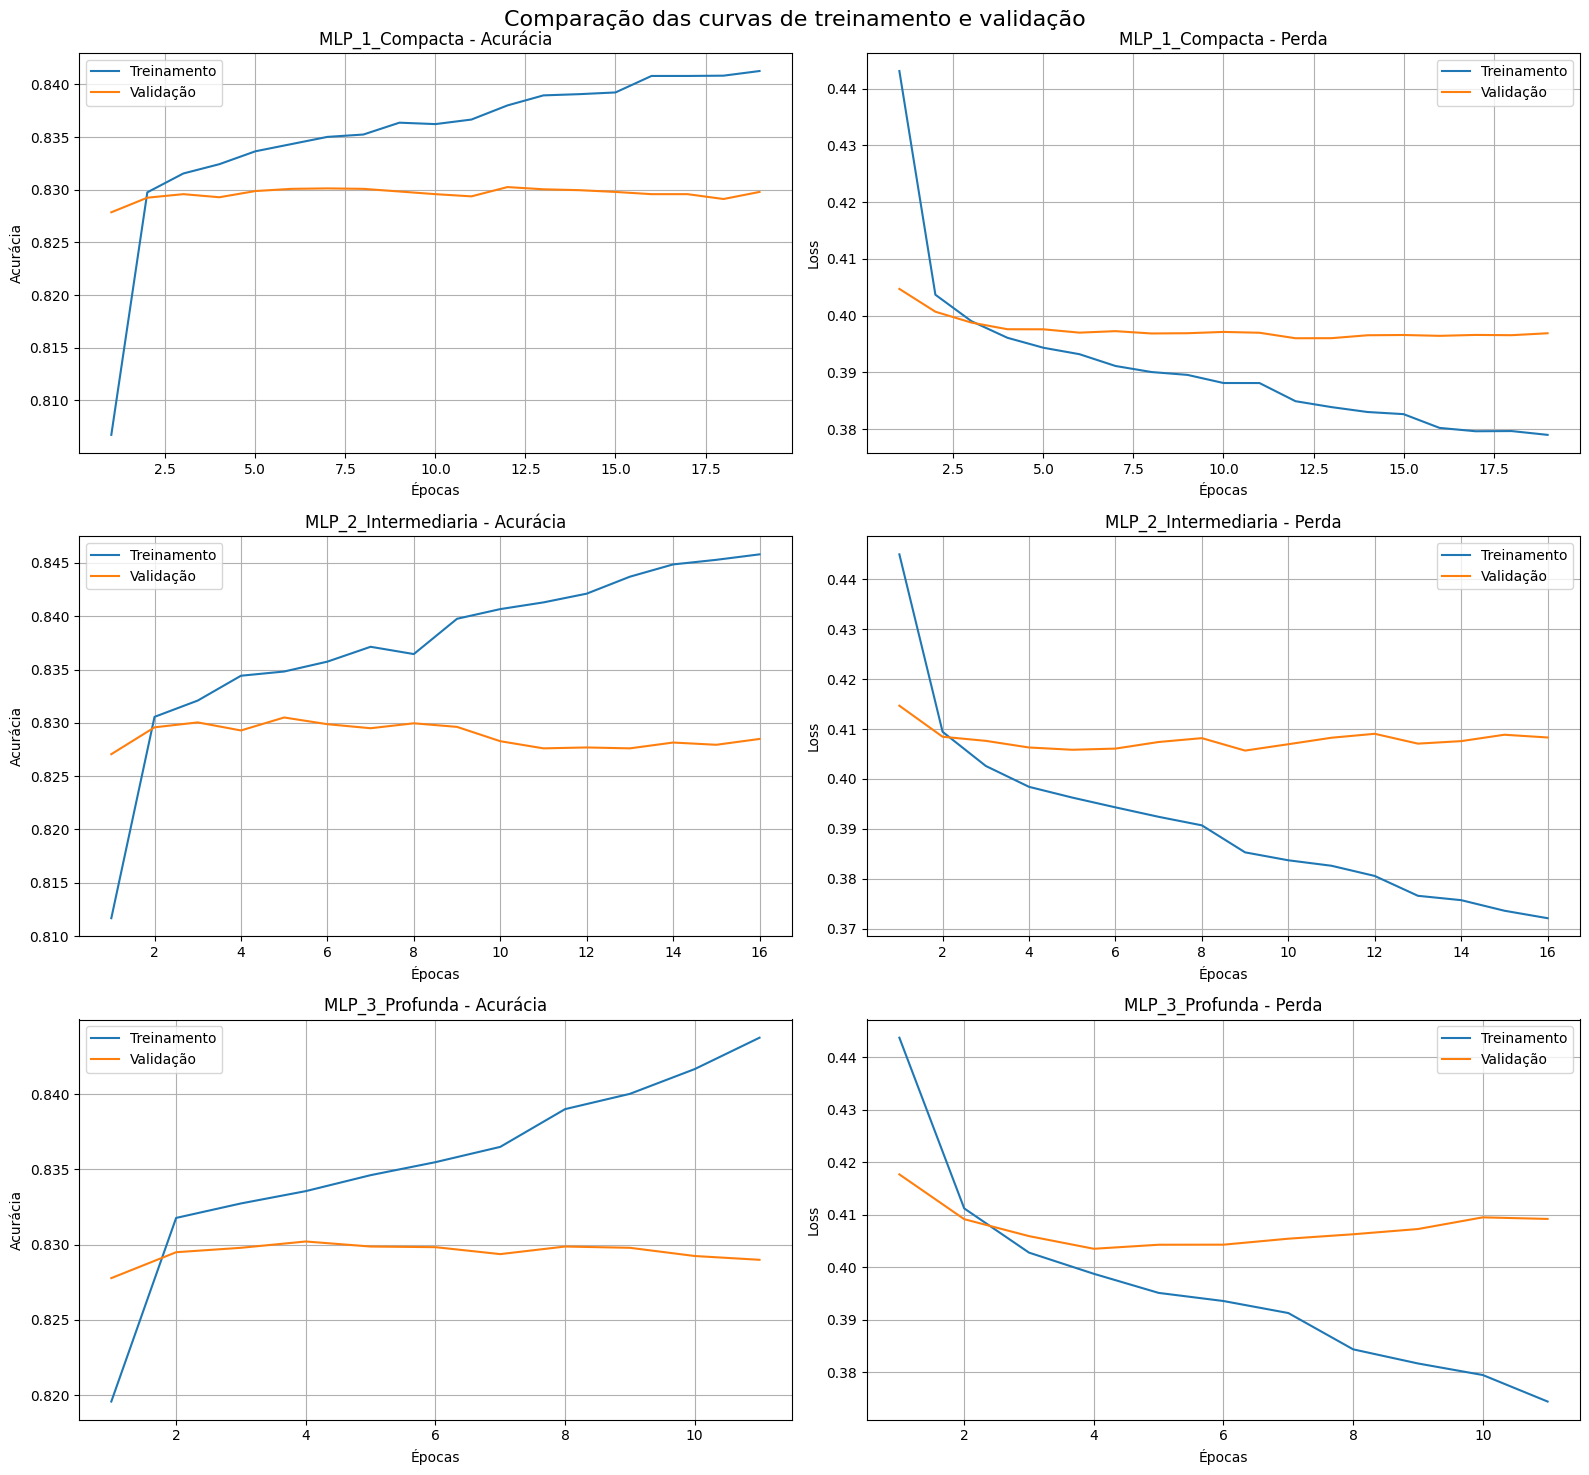

In [ ]:

import matplotlib.pyplot as plt

nomes_modelos = [
    "MLP_1_Compacta",
    "MLP_2_Intermediaria",
    "MLP_3_Profunda"
]

fig, eixos = plt.subplots(3, 2, figsize=(16, 15))

for i, nome in enumerate(nomes_modelos):

    hist = historicos[nome].history
    epocas = range(1, len(hist["loss"]) + 1)

    # Gráfico de acurácia
    eixos[i, 0].plot(
        epocas,
        hist["accuracy"],
        label="Treinamento"
    )

    eixos[i, 0].plot(
        epocas,
        hist["val_accuracy"],
        label="Validação"
    )

    eixos[i, 0].set_title(f"{nome} - Acurácia")
    eixos[i, 0].set_xlabel("Épocas")
    eixos[i, 0].set_ylabel("Acurácia")
    eixos[i, 0].legend()
    eixos[i, 0].grid(True)

    # Gráfico de perda
    eixos[i, 1].plot(
        epocas,
        hist["loss"],
        label="Treinamento"
    )

    eixos[i, 1].plot(
        epocas,
        hist["val_loss"],
        label="Validação"
    )

    eixos[i, 1].set_title(f"{nome} - Perda")
    eixos[i, 1].set_xlabel("Épocas")
    eixos[i, 1].set_ylabel("Loss")
    eixos[i, 1].legend()
    eixos[i, 1].grid(True)

plt.suptitle(
    "Comparação das curvas de treinamento e validação",
    fontsize=16
)

plt.tight_layout()
plt.show()


In [ ]:

print("ANÁLISE DOS HISTÓRICOS DE TREINAMENTO")
print("=" * 65)

for nome in nomes_modelos:

    hist = historicos[nome].history

    melhor_epoca = hist["val_loss"].index(min(hist["val_loss"])) + 1

    melhor_val_loss = min(hist["val_loss"])
    melhor_val_accuracy = max(hist["val_accuracy"])

    accuracy_final = hist["accuracy"][-1]
    val_accuracy_final = hist["val_accuracy"][-1]

    diferenca_accuracy = accuracy_final - val_accuracy_final

    print(f"\nModelo: {nome}")
    print(f"Épocas executadas: {len(hist['loss'])}")
    print(f"Melhor época pela val_loss: {melhor_epoca}")
    print(f"Melhor val_loss: {melhor_val_loss:.4f}")
    print(f"Melhor val_accuracy: {melhor_val_accuracy:.4f}")
    print(f"Acurácia final de treino: {accuracy_final:.4f}")
    print(f"Acurácia final de validação: {val_accuracy_final:.4f}")
    print(f"Diferença treino-validação: {diferenca_accuracy:.4f}")


ANÁLISE DOS HISTÓRICOS DE TREINAMENTO

Modelo: MLP_1_Compacta
Épocas executadas: 19
Melhor época pela val_loss: 12
Melhor val_loss: 0.3960
Melhor val_accuracy: 0.8302
Acurácia final de treino: 0.8413
Acurácia final de validação: 0.8298
Diferença treino-validação: 0.0115

Modelo: MLP_2_Intermediaria
Épocas executadas: 16
Melhor época pela val_loss: 9
Melhor val_loss: 0.4057
Melhor val_accuracy: 0.8305
Acurácia final de treino: 0.8458
Acurácia final de validação: 0.8285
Diferença treino-validação: 0.0173

Modelo: MLP_3_Profunda
Épocas executadas: 11
Melhor época pela val_loss: 4
Melhor val_loss: 0.4035
Melhor val_accuracy: 0.8302
Acurácia final de treino: 0.8438
Acurácia final de validação: 0.8290
Diferença treino-validação: 0.0148


### Interpretação

| Modelo | Melhor época (`val_loss`) | Diferença de acurácia treino − validação na última época | Leitura |
|---|---|---|---|
| MLP_1_Compacta | 12 de 19 | 1,15 p.p. | `val_loss` estabiliza em torno da época 12 enquanto a perda de treino continua caindo: **overfitting leve** |
| MLP_2_Intermediaria | 9 de 16 | 1,73 p.p. | Gap maior; validação piora após a melhor época |
| MLP_3_Profunda | 4 de 11 | 1,48 p.p. | `val_loss` **sobe** logo após a época 4 (0,4035 → ≈ 0,409): overfitting mais precoce e mais claro |

- **Overfitting:** quanto maior a rede, mais cedo a perda de validação deixa de melhorar. O *early stopping* com restauração dos melhores pesos contém esse efeito (os modelos avaliados usam os pesos da melhor época, não os da última).
- **Underfitting:** não parece ser o problema. A acurácia de treino fica em torno de 84% e a de validação em 83%; nenhuma arquitetura maior melhora esse patamar. O teto vem da **informação disponível** (seis atributos categóricos de contexto), e não da falta de capacidade da rede.
- As diferenças de acurácia entre treino e validação citadas acima usam a **última época**, antes da restauração dos melhores pesos.

---
## 8. Seleção da arquitetura (validação)

Matriz de confusão e relatório de classificação da **MLP_1_Compacta** no conjunto de **validação** (limiar 0,50). Linhas: classe real; colunas: classe prevista; `0` = Furto, `1` = Roubo.

In [ ]:

from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np

# Selecionar o modelo compacto
modelo_selecionado = modelos["MLP_1_Compacta"]

# Previsões sobre o conjunto de validação
probabilidades_val = modelo_selecionado.predict(
    X_val_proc,
    verbose=0
).ravel()

previsoes_val = (probabilidades_val >= 0.5).astype(int)

# Matriz de confusão
matriz = confusion_matrix(y_val, previsoes_val)

print("MATRIZ DE CONFUSÃO — MLP COMPACTA")
print("=" * 45)
print("Linhas: classes reais | Colunas: classes previstas")
print("Ordem das classes: 0 = Furto | 1 = Roubo")
print(matriz)

print("\nRELATÓRIO DE CLASSIFICAÇÃO")
print("=" * 45)
print(classification_report(
    y_val,
    previsoes_val,
    target_names=["Furto", "Roubo"],
    digits=4
))

print("MÉTRICAS GERAIS")
print("=" * 45)
print(f"Accuracy:  {accuracy_score(y_val, previsoes_val):.4f}")
print(f"Precision: {precision_score(y_val, previsoes_val):.4f}")
print(f"Recall:    {recall_score(y_val, previsoes_val):.4f}")
print(f"F1-score:  {f1_score(y_val, previsoes_val):.4f}")


MATRIZ DE CONFUSÃO — MLP COMPACTA
Linhas: classes reais | Colunas: classes previstas
Ordem das classes: 0 = Furto | 1 = Roubo
[[12919  2166]
 [ 1879  6865]]

RELATÓRIO DE CLASSIFICAÇÃO
              precision    recall  f1-score   support

       Furto     0.8730    0.8564    0.8646     15085
       Roubo     0.7602    0.7851    0.7724      8744

    accuracy                         0.8302     23829
   macro avg     0.8166    0.8208    0.8185     23829
weighted avg     0.8316    0.8302    0.8308     23829

MÉTRICAS GERAIS
Accuracy:  0.8302
Precision: 0.7602
Recall:    0.7851
F1-score:  0.7724


### Decisão

Escolhemos a **MLP_1_Compacta**. A escolha foi feita apenas com dados de **validação**:

1. Menor perda de validação (**0,3960**, contra 0,4035 e 0,4057).
2. Maior F1 macro (0,8185) e acurácia igual à melhor (0,8302).
3. Menor capacidade (20.929 parâmetros treináveis, cerca de 5,6 vezes menos que a MLP_3) e menor sinal de overfitting.

A diferença de desempenho entre as três arquiteturas é muito pequena; o critério decisivo é, portanto, a **parcimônia**: com resultados equivalentes, preferimos o modelo mais simples, mais rápido e mais fácil de explicar.

---
## 9. Experimentos complementares (limiar, pesos de classe e regularização)

Estes testes foram feitos **sobre a MLP_1_Compacta** e avaliados na validação, para verificar se ajustes simples melhorariam o resultado.

### 9.1 Limiar de decisão

O limiar padrão é 0,50. Variando de 0,30 a 0,70, o maior F1 macro na validação ocorre em **0,45** (0,8210 contra 0,8185 em 0,50). Esse limiar troca precision por recall da classe roubo: **−1,06 p.p. de precision e +2,52 p.p. de recall**. Mais limiar baixo = mais roubos detectados, porém mais furtos classificados como roubo.

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import pandas as pd
import numpy as np

# Probabilidades produzidas pela MLP compacta na validação
probabilidades = modelos["MLP_1_Compacta"].predict(
    X_val_proc,
    verbose=0
).ravel()

y_real = np.asarray(y_val).ravel()

# Testar diferentes limiares
limiares = np.arange(0.30, 0.71, 0.05)

resultados_limiar = []

for limiar in limiares:

    previsoes = (probabilidades >= limiar).astype(int)

    resultados_limiar.append({
        "Limiar": round(float(limiar), 2),
        "Accuracy": accuracy_score(y_real, previsoes),
        "Precision_Roubo": precision_score(
            y_real, previsoes, zero_division=0
        ),
        "Recall_Roubo": recall_score(
            y_real, previsoes, zero_division=0
        ),
        "F1_Roubo": f1_score(
            y_real, previsoes, zero_division=0
        ),
        "F1_Macro": f1_score(
            y_real, previsoes, average="macro"
        )
    })

df_limiares = pd.DataFrame(resultados_limiar)

print("COMPARAÇÃO DE LIMIARES — CONJUNTO DE VALIDAÇÃO")
print("=" * 75)
print(df_limiares.round(4).to_string(index=False))

# Seleção pelo F1 macro, mantendo o critério de comparação anterior
melhor_limiar = df_limiares.loc[
    df_limiares["F1_Macro"].idxmax()
]

print("\nMELHOR LIMIAR PELO F1 MACRO")
print("=" * 45)
print(melhor_limiar.to_string())

# Comparação com o limiar original de 0.50
resultado_original = df_limiares[
    df_limiares["Limiar"] == 0.50
].iloc[0]

print("\nCOMPARAÇÃO COM O LIMIAR ORIGINAL (0.50)")
print("=" * 45)

for metrica in [
    "Accuracy",
    "Precision_Roubo",
    "Recall_Roubo",
    "F1_Roubo",
    "F1_Macro"
]:
    diferenca = melhor_limiar[metrica] - resultado_original[metrica]
    print(f"{metrica}: {diferenca:+.4f}")


COMPARAÇÃO DE LIMIARES — CONJUNTO DE VALIDAÇÃO
 Limiar  Accuracy  Precision_Roubo  Recall_Roubo  F1_Roubo  F1_Macro
   0.30    0.8165           0.7000        0.8749    0.7778    0.8108
   0.35    0.8232           0.7156        0.8599    0.7812    0.8164
   0.40    0.8282           0.7334        0.8354    0.7811    0.8198
   0.45    0.8310           0.7496        0.8103    0.7787    0.8210
   0.50    0.8302           0.7602        0.7851    0.7724    0.8185
   0.55    0.8292           0.7728        0.7571    0.7649    0.8154
   0.60    0.8246           0.7880        0.7142    0.7493    0.8072
   0.65    0.8154           0.8054        0.6554    0.7227    0.7922
   0.70    0.8013           0.8225        0.5846    0.6835    0.7693

MELHOR LIMIAR PELO F1 MACRO
Limiar             0.450000
Accuracy           0.831046
Precision_Roubo    0.749577
Recall_Roubo       0.810270
F1_Roubo           0.778743
F1_Macro           0.821046

COMPARAÇÃO COM O LIMIAR ORIGINAL (0.50)
Accuracy: +0.0008
Precisi

### 9.2 Pesos de classe balanceados e regularização L2 (execução)

In [ ]:

import tensorflow as tf
import numpy as np
import pandas as pd

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Preparar os rótulos
y_train_np = np.asarray(y_train).ravel()
y_val_np = np.asarray(y_val).ravel()

# 2. Calcular pesos automaticamente para cada classe
classes = np.unique(y_train_np)

pesos = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_np
)

class_weights = {
    int(classe): float(peso)
    for classe, peso in zip(classes, pesos)
}

print("PESOS ATRIBUÍDOS ÀS CLASSES")
print("=" * 45)
print("0 = Furto:", round(class_weights[0], 4))
print("1 = Roubo:", round(class_weights[1], 4))

# 3. Clonar a arquitetura original, sem copiar os pesos treinados
modelo_balanceado = tf.keras.models.clone_model(
    modelos["MLP_1_Compacta"]
)

# Reutilizar a taxa de aprendizado registrada no modelo original
learning_rate_original = float(
    modelos["MLP_1_Compacta"].optimizer.learning_rate.numpy()
)

modelo_balanceado.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=learning_rate_original
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# 4. Configurar controle de treinamento
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.000001
)

# 5. Treinar utilizando pesos balanceados
historico_balanceado = modelo_balanceado.fit(
    X_train_proc,
    y_train_np,
    validation_data=(X_val_proc, y_val_np),
    epochs=50,
    batch_size=256,
    class_weight=class_weights,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

# 6. Gerar probabilidades na validação
probabilidades_balanceadas = modelo_balanceado.predict(
    X_val_proc,
    verbose=0
).ravel()

# 7. Comparar modelo original e balanceado
probabilidades_originais = modelos[
    "MLP_1_Compacta"
].predict(X_val_proc, verbose=0).ravel()

def calcular_metricas(y_real, probabilidades, limiar):
    previsoes = (probabilidades >= limiar).astype(int)

    return {
        "Accuracy": accuracy_score(y_real, previsoes),
        "Precision_Roubo": precision_score(
            y_real, previsoes, zero_division=0
        ),
        "Recall_Roubo": recall_score(
            y_real, previsoes, zero_division=0
        ),
        "F1_Roubo": f1_score(
            y_real, previsoes, zero_division=0
        ),
        "F1_Macro": f1_score(
            y_real, previsoes, average="macro"
        )
    }

comparacao_balanceamento = []

for nome, probabilidades in [
    ("Original", probabilidades_originais),
    ("Balanceada", probabilidades_balanceadas)
]:
    for limiar in [0.45, 0.50]:
        metricas = calcular_metricas(
            y_val_np,
            probabilidades,
            limiar
        )

        comparacao_balanceamento.append({
            "Modelo": nome,
            "Limiar": limiar,
            **metricas
        })

df_comparacao_balanceamento = pd.DataFrame(
    comparacao_balanceamento
)

print("\nCOMPARAÇÃO — VALIDAÇÃO")
print("=" * 85)
print(
    df_comparacao_balanceamento
    .round(4)
    .to_string(index=False)
)

print("\nÉPOCAS EXECUTADAS:", len(historico_balanceado.history["loss"]))
print("MELHOR VAL_LOSS:", round(
    min(historico_balanceado.history["val_loss"]), 4
))


PESOS ATRIBUÍDOS ÀS CLASSES
0 = Furto: 0.7898
1 = Roubo: 1.3627
Epoch 1/50
435/435 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.7325 - loss: 0.5753 - val_accuracy: 0.8054 - val_loss: 0.4598 - learning_rate: 1.2500e-04
Epoch 2/50
435/435 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8116 - loss: 0.4512 - val_accuracy: 0.8134 - val_loss: 0.4387 - learning_rate: 1.2500e-04
Epoch 3/50
435/435 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8171 - loss: 0.4381 - val_accuracy: 0.8156 - val_loss: 0.4315 - learning_rate: 1.2500e-04
Epoch 4/50
435/435 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8203 - loss: 0.4313 - val_accuracy: 0.8179 - val_loss: 0.4275 - learning_rate: 1.2500e-04
Epoch 5/50
435/435 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8212 - loss: 0.4280 - val_accuracy: 0.8186 - val_loss: 0.4255 - learning_rate: 1.2500e-04
Epoch 6/50
435/435 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8217 - loss: 0.4252 - val_accuracy: 0.8193 - val_loss: 0.4229 - learning_rate: 1.2500e-04

In [ ]:

import tensorflow as tf
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

modelo_base = modelos["MLP_1_Compacta"]

# 1. Clonar a arquitetura e aumentar somente a regularização L2
def configurar_l2(camada):
    config = camada.get_config()

    if isinstance(camada, tf.keras.layers.Dense) and camada.units != 1:
        config["kernel_regularizer"] = tf.keras.regularizers.l2(0.001)

    return camada.__class__.from_config(config)

modelo_l2 = tf.keras.models.clone_model(
    modelo_base,
    clone_function=configurar_l2
)

# 2. Manter o otimizador e a taxa de aprendizado originais
modelo_l2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=float(
            modelo_base.optimizer.learning_rate.numpy()
        )
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# 3. Callbacks
early_stopping_l2 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

reduce_lr_l2 = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.000001
)

# 4. Treinar sem class_weight, alterando apenas a intensidade de L2
historico_l2 = modelo_l2.fit(
    X_train_proc,
    np.asarray(y_train).ravel(),
    validation_data=(
        X_val_proc,
        np.asarray(y_val).ravel()
    ),
    epochs=50,
    batch_size=256,
    callbacks=[early_stopping_l2, reduce_lr_l2],
    verbose=1
)

# 5. Avaliar os resultados após restaurar os melhores pesos
y_val_np = np.asarray(y_val).ravel()

perda_treino_l2, acc_treino_l2 = modelo_l2.evaluate(
    X_train_proc,
    np.asarray(y_train).ravel(),
    verbose=0
)

perda_validacao_l2, acc_validacao_l2 = modelo_l2.evaluate(
    X_val_proc,
    y_val_np,
    verbose=0
)

# 6. Gerar probabilidades
probabilidades_l2 = modelo_l2.predict(
    X_val_proc,
    verbose=0
).ravel()

probabilidades_originais = modelo_base.predict(
    X_val_proc,
    verbose=0
).ravel()

# 7. Comparar modelos em dois limiares
def metricas_modelo(y_real, probabilidades, limiar):
    previsoes = (probabilidades >= limiar).astype(int)

    return {
        "Accuracy": accuracy_score(y_real, previsoes),
        "Precision_Roubo": precision_score(
            y_real, previsoes, zero_division=0
        ),
        "Recall_Roubo": recall_score(
            y_real, previsoes, zero_division=0
        ),
        "F1_Roubo": f1_score(
            y_real, previsoes, zero_division=0
        ),
        "F1_Macro": f1_score(
            y_real, previsoes, average="macro"
        )
    }

comparacao_l2 = []

for nome, probabilidades in [
    ("Original_L2_0.0001", probabilidades_originais),
    ("Regularizada_L2_0.001", probabilidades_l2)
]:
    for limiar in [0.45, 0.50]:
        comparacao_l2.append({
            "Modelo": nome,
            "Limiar": limiar,
            **metricas_modelo(y_val_np, probabilidades, limiar)
        })

df_comparacao_l2 = pd.DataFrame(comparacao_l2)

print("\nCOMPARAÇÃO DOS MODELOS — VALIDAÇÃO")
print("=" * 90)
print(df_comparacao_l2.round(4).to_string(index=False))

print("\nRESULTADOS DO TREINAMENTO L2")
print("=" * 55)
print("Épocas executadas:", len(historico_l2.history["loss"]))
print("Menor val_loss:", round(
    min(historico_l2.history["val_loss"]), 4
))
print("Loss treino após restauração:", round(perda_treino_l2, 4))
print("Loss validação após restauração:", round(perda_validacao_l2, 4))
print("Accuracy treino:", round(acc_treino_l2, 4))
print("Accuracy validação:", round(acc_validacao_l2, 4))
print("Diferença treino-validação:",
      round(acc_treino_l2 - acc_validacao_l2, 4))


Epoch 1/50
435/435 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7349 - loss: 0.6640 - val_accuracy: 0.8109 - val_loss: 0.5207 - learning_rate: 1.2500e-04
Epoch 2/50
435/435 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8159 - loss: 0.5013 - val_accuracy: 0.8189 - val_loss: 0.4731 - learning_rate: 1.2500e-04
Epoch 3/50
435/435 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8223 - loss: 0.4698 - val_accuracy: 0.8214 - val_loss: 0.4535 - learning_rate: 1.2500e-04
Epoch 4/50
435/435 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8247 - loss: 0.4536 - val_accuracy: 0.8248 - val_loss: 0.4424 - learning_rate: 1.2500e-04
Epoch 5/50
435/435 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8270 - loss: 0.4437 - val_accuracy: 0.8257 - val_loss: 0.4352 - learning_rate: 1.2500e-04
Epoch 6/50
435/435 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8268 - loss: 0.4365 - val_accuracy: 0.8261 - val_loss: 0.4299 - learning_rate: 1.2500e-04
Epoch 7/50
435/435 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 

### Resumo dos experimentos 9.2 e decisão

| Variante (validação, limiar 0,50) | Acurácia | Precision (roubo) | Recall (roubo) | F1 macro |
|---|---|---|---|---|
| Original (L2 = 0,0001) | 0,8302 | 0,7602 | 0,7851 | 0,8185 |
| Pesos de classe balanceados (furto 0,79 · roubo 1,36) | 0,8230 | 0,7184 | 0,8512 | 0,8157 |
| L2 = 0,001 | 0,8301 | 0,7566 | 0,7917 | 0,8189 |

**Leitura.** Os pesos de classe aumentam o recall do roubo (+6,6 p.p.), mas derrubam a precision (−4,2 p.p.) e **não melhoram** o F1 macro. A regularização L2 mais forte praticamente não altera o resultado (+0,0004 no F1 macro, dentro da variação esperada).

> **Ressalva metodológica.** Nestes dois experimentos, o modelo foi clonado e recompilado reaproveitando `optimizer.learning_rate`. Como essa leitura ocorre **depois** do treino original (cujo `ReduceLROnPlateau` já havia reduzido a taxa), os dois experimentos partiram de **1,25 × 10⁻⁴**, e não de 1 × 10⁻³. Por isso a comparação com o modelo original **não é totalmente controlada** e deve ser lida como indicativa. Além disso, a perda (`val_loss`) do modelo com L2 = 0,001 inclui um termo de penalização maior e **não é comparável** com a dos demais. Esses testes **não alteram** a comparação das três arquiteturas (seção 8), cujo treino usou taxa inicial 1 × 10⁻³.

### 9.3 Decisão sobre o limiar

Mantemos o **limiar 0,50** como configuração final, por três motivos:

1. O ganho do limiar 0,45 é marginal (+0,0025 no F1 macro) e vem de uma troca de precision por recall, não de um modelo melhor.
2. Com 0,50 a avaliação de teste e a aplicação web usam exatamente a mesma regra de decisão, e os números do relatório correspondem ao modelo publicado.
3. Se o objetivo fosse **detectar mais roubos** (priorizar recall), o limiar 0,45 seria uma alternativa justificável.

---
## 10. Avaliação final no conjunto de teste

O conjunto de teste foi reservado até aqui: não participou do treino, da escolha da arquitetura nem da análise de limiar. A avaliação abaixo é feita **uma única vez**, com o modelo escolhido e o limiar 0,50.

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Avaliação final no conjunto de teste
probabilidades_teste = modelo_selecionado.predict(
    X_test_proc,
    verbose=0
).ravel()

previsoes_teste = (probabilidades_teste >= 0.5).astype(int)

# Métricas
print("AVALIAÇÃO FINAL — CONJUNTO DE TESTE")
print("=" * 50)

print(f"Accuracy:  {accuracy_score(y_test, previsoes_teste):.4f}")
print(f"Precision: {precision_score(y_test, previsoes_teste):.4f}")
print(f"Recall:    {recall_score(y_test, previsoes_teste):.4f}")
print(f"F1-score:  {f1_score(y_test, previsoes_teste):.4f}")
print(f"F1 macro:  {f1_score(y_test, previsoes_teste, average='macro'):.4f}")

print("\nRELATÓRIO DE CLASSIFICAÇÃO")
print("=" * 50)

print(classification_report(
    y_test,
    previsoes_teste,
    target_names=["Furto", "Roubo"],
    digits=4
))

print("\nMATRIZ DE CONFUSÃO")
print("=" * 50)

print(confusion_matrix(y_test, previsoes_teste))


AVALIAÇÃO FINAL — CONJUNTO DE TESTE
Accuracy:  0.8319
Precision: 0.7587
Recall:    0.7947
F1-score:  0.7763
F1 macro:  0.8208

RELATÓRIO DE CLASSIFICAÇÃO
              precision    recall  f1-score   support

       Furto     0.8776    0.8535    0.8654     15086
       Roubo     0.7587    0.7947    0.7763      8743

    accuracy                         0.8319     23829
   macro avg     0.8182    0.8241    0.8208     23829
weighted avg     0.8340    0.8319    0.8327     23829


MATRIZ DE CONFUSÃO
[[12876  2210]
 [ 1795  6948]]


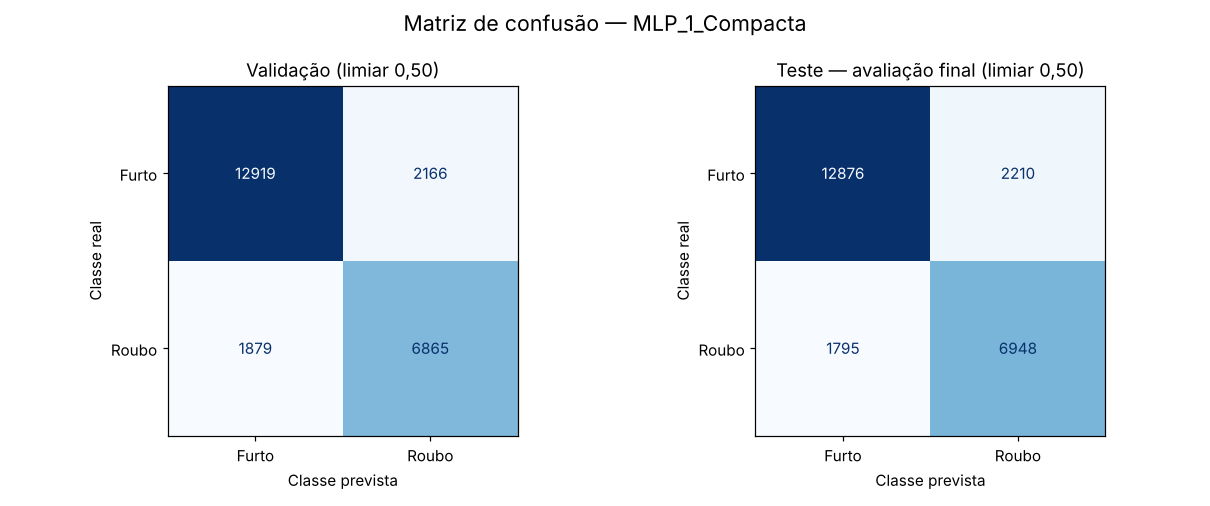

In [ ]:
# ==========================================
# MATRIZES DE CONFUSÃO — MLP_1_Compacta
# ==========================================
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

rotulos = ["Furto", "Roubo"]

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.6))

for eixo, titulo, y_real, y_prev in [
    (eixos[0], "Validação (limiar 0,50)", y_val, previsoes_val),
    (eixos[1], "Teste — avaliação final (limiar 0,50)", y_test, previsoes_teste),
]:
    ConfusionMatrixDisplay.from_predictions(
        y_real,
        y_prev,
        display_labels=rotulos,
        cmap="Blues",
        values_format="d",
        colorbar=False,
        ax=eixo,
    )
    eixo.set_title(titulo)
    eixo.set_xlabel("Classe prevista")
    eixo.set_ylabel("Classe real")

plt.suptitle("Matriz de confusão — MLP_1_Compacta", fontsize=14)
plt.tight_layout()
plt.show()

### Resultado final

| Conjunto | Acurácia | Precision (roubo) | Recall (roubo) | F1 (roubo) | F1 macro |
|---|---|---|---|---|---|
| Validação | 0,8302 | 0,7602 | 0,7851 | 0,7724 | 0,8185 |
| **Teste** | **0,8319** | **0,7587** | **0,7947** | **0,7763** | **0,8208** |

A proximidade entre validação e teste (diferença de 0,17 p.p. na acurácia) indica **boa capacidade de generalização**, sem sinais de que a seleção tenha se ajustado ao conjunto de validação.

**Erros no teste (matriz de confusão):**

| | Previsto: Furto | Previsto: Roubo |
|---|---|---|
| **Real: Furto** | 12.876 | 2.210 (14,6% dos furtos) |
| **Real: Roubo** | 1.795 (20,5% dos roubos) | 6.948 |

O modelo erra mais ao classificar **roubos como furtos** (20,5% dos roubos) do que o inverso (14,6% dos furtos). Os resultados mostram utilidade como classificador experimental, mas **não justificam o uso isolado em decisões operacionais** de segurança pública.

---
## 11. Exportação do modelo e aplicação web

Foram exportados: o **modelo** (`modelo_mlp.keras`), o **pré-processador ajustado** (`preprocessor.joblib`, garante o mesmo one-hot do treino) e a **configuração** (`configuracao.json`, com atributos, classes e limiar de decisão **0,50**).

A aplicação (`app.py`, em Streamlit) reconstrói o formulário a partir das categorias aprendidas pelo codificador, aplica o mesmo pré-processamento, calcula a probabilidade de roubo e de furto e mostra a classe estimada. Aplicação publicada: https://spmobilecrimeclassifier.streamlit.app/

> A interpretação correta da saída é: *dado que uma ocorrência tem estas características, o modelo atribui X% de probabilidade à classe roubo*. **Não** significa que existe X% de chance de ocorrer um roubo naquele local e horário.

In [ ]:

import os
import json
import joblib

# Criar diretório para os arquivos da aplicação
diretorio = "/content/modelo_app"
os.makedirs(diretorio, exist_ok=True)

# 1. Exportar a MLP original
modelo_exportacao = modelos["MLP_1_Compacta"]

caminho_modelo = os.path.join(
    diretorio, "modelo_mlp.keras"
)

modelo_exportacao.save(caminho_modelo)

# 2. Exportar o pré-processador ajustado
caminho_preprocessor = os.path.join(
    diretorio, "preprocessor.joblib"
)

joblib.dump(preprocessor, caminho_preprocessor)

# 3. Criar configuração da aplicação
configuracao = {
    "nome_modelo": "MLP_1_Compacta",
    "limiar_classificacao": 0.50,
    "classes": {
        "0": "Furto",
        "1": "Roubo"
    },
    "features": [
        "BAIRRO",
        "MES",
        "DIA_SEMANA",
        "DESCR_PERIODO",
        "DESCR_TIPOLOCAL",
        "DESCR_SUBTIPOLOCAL"
    ],
    "quantidade_features_processadas": int(X_train_proc.shape[1]),
    "fonte_dados": "Secretaria da Segurança Pública do Estado de São Paulo",
    "recorte": "Ocorrências envolvendo celulares na cidade de São Paulo em 2025"
}

caminho_config = os.path.join(
    diretorio, "configuracao.json"
)

with open(caminho_config, "w", encoding="utf-8") as arquivo:
    json.dump(
        configuracao,
        arquivo,
        ensure_ascii=False,
        indent=4
    )

# 4. Conferir os arquivos
print("ARQUIVOS EXPORTADOS")
print("=" * 55)

for arquivo in os.listdir(diretorio):
    caminho = os.path.join(diretorio, arquivo)
    tamanho = os.path.getsize(caminho) / (1024 * 1024)

    print(f"{arquivo}: {tamanho:.2f} MB")

print("\nExportação concluída.")


ARQUIVOS EXPORTADOS
modelo_mlp.keras: 0.27 MB
configuracao.json: 0.00 MB
preprocessor.joblib: 0.07 MB

Exportação concluída.


In [ ]:

import tensorflow as tf
import joblib
import json
import numpy as np
import os

# Carregar os três componentes exportados
modelo_teste = tf.keras.models.load_model(
    "/content/modelo_app/modelo_mlp.keras"
)

preprocessor_teste = joblib.load(
    "/content/modelo_app/preprocessor.joblib"
)

with open(
    "/content/modelo_app/configuracao.json",
    "r",
    encoding="utf-8"
) as arquivo:
    config_teste = json.load(arquivo)

# Transformar uma ocorrência real da base
amostra = X_val.head(1)

entrada = preprocessor_teste.transform(amostra)

# Gerar probabilidade
probabilidade = float(
    modelo_teste.predict(entrada, verbose=0)[0][0]
)

# Aplicar o limiar configurado
limiar = config_teste["limiar_classificacao"]

classe = int(probabilidade >= limiar)

print("TESTE DE INTEGRAÇÃO")
print("=" * 55)
print("Formato da entrada:", entrada.shape)
print("Probabilidade de roubo:", round(probabilidade, 4))
print("Classe prevista:", config_teste["classes"][str(classe)])
print("Limiar:", limiar)
print("Modelo carregado:", modelo_teste.name)
print("Pré-processador carregado:", type(preprocessor_teste).__name__)


In [ ]:

codigo_app = r'''
import json
import joblib
import streamlit as st
import pandas as pd
import numpy as np
import tensorflow as tf
from pathlib import Path

# --------------------------------------------------
# CONFIGURAÇÕES
# --------------------------------------------------

PASTA = Path(__file__).parent / "modelo_app"

st.set_page_config(
    page_title="Classificação de Ocorrências",
    page_icon="🔎",
    layout="centered"
)

@st.cache_resource
def carregar_componentes():
    modelo = tf.keras.models.load_model(
        PASTA / "modelo_mlp.keras"
    )

    preprocessor = joblib.load(
        PASTA / "preprocessor.joblib"
    )

    with open(
        PASTA / "configuracao.json",
        "r",
        encoding="utf-8"
    ) as arquivo:
        config = json.load(arquivo)

    return modelo, preprocessor, config


modelo, preprocessor, config = carregar_componentes()

# Recuperar categorias aprendidas no treinamento
encoder = preprocessor.named_transformers_["categoricas"]

colunas = config["features"]

categorias = {
    coluna: [str(valor) for valor in valores]
    for coluna, valores in zip(colunas, encoder.categories_)
}

# --------------------------------------------------
# INTERFACE
# --------------------------------------------------

st.title("Classificação de Ocorrências")
st.subheader("Segurança pública inteligente em São Paulo")

st.write(
    "Ferramenta experimental de classificação de ocorrências "
    "envolvendo celulares, com base em características do fato."
)

st.info(
    "Preencha os atributos de uma ocorrência registrada ou hipotética "
    "para obter a classificação estimada pelo modelo."
)

st.divider()

st.header("Características da ocorrência")

with st.form("formulario_ocorrencia"):

    bairro = st.selectbox(
        "Bairro",
        options=categorias["BAIRRO"]
    )

    meses = sorted(
        categorias["MES"],
        key=lambda valor: int(valor)
    )

    mes = st.selectbox(
        "Mês da ocorrência",
        options=meses,
        format_func=lambda valor: {
            "1": "Janeiro", "2": "Fevereiro",
            "3": "Março", "4": "Abril",
            "5": "Maio", "6": "Junho",
            "7": "Julho", "8": "Agosto",
            "9": "Setembro", "10": "Outubro",
            "11": "Novembro", "12": "Dezembro"
        }.get(valor, valor)
    )

    dias = sorted(
        categorias["DIA_SEMANA"],
        key=lambda valor: int(valor)
    )

    nomes_dias = {
        "0": "Segunda-feira",
        "1": "Terça-feira",
        "2": "Quarta-feira",
        "3": "Quinta-feira",
        "4": "Sexta-feira",
        "5": "Sábado",
        "6": "Domingo"
    }

    dia_semana = st.selectbox(
        "Dia da semana",
        options=dias,
        format_func=lambda valor: nomes_dias.get(valor, valor)
    )

    periodo = st.selectbox(
        "Período do dia",
        options=categorias["DESCR_PERIODO"]
    )

    tipo_local = st.selectbox(
        "Tipo de local",
        options=categorias["DESCR_TIPOLOCAL"]
    )

    subtipo_local = st.selectbox(
        "Subtipo do local",
        options=categorias["DESCR_SUBTIPOLOCAL"]
    )

    enviar = st.form_submit_button(
        "Classificar ocorrência",
        use_container_width=True
    )

# --------------------------------------------------
# CLASSIFICAÇÃO
# --------------------------------------------------

if enviar:

    dados = pd.DataFrame([{
        "BAIRRO": bairro,
        "MES": mes,
        "DIA_SEMANA": dia_semana,
        "DESCR_PERIODO": periodo,
        "DESCR_TIPOLOCAL": tipo_local,
        "DESCR_SUBTIPOLOCAL": subtipo_local
    }], columns=colunas)

    # Aplicar o mesmo pré-processamento do treinamento
    entrada_processada = preprocessor.transform(dados)

    # Verificar dimensão esperada
    if entrada_processada.shape[1] != config[
        "quantidade_features_processadas"
    ]:
        st.error("Erro: dimensão dos atributos incompatível.")
        st.stop()

    # Prever probabilidade de roubo
    prob_roubo = float(
        modelo.predict(
            entrada_processada,
            verbose=0
        )[0][0]
    )

    prob_furto = 1 - prob_roubo

    # Aplicar limiar selecionado na validação
    limiar = config["limiar_classificacao"]

    classe = int(prob_roubo >= limiar)

    resultado = config["classes"][str(classe)]

    st.divider()
    st.header("Resultado da classificação")

    if resultado == "Roubo":
        st.error("Classificação estimada: ROUBO")
    else:
        st.success("Classificação estimada: FURTO")

    st.write("Probabilidades estimadas pelo modelo:")

    col1, col2 = st.columns(2)

    with col1:
        st.metric(
            "Furto",
            f"{prob_furto * 100:.2f}%"
        )

    with col2:
        st.metric(
            "Roubo",
            f"{prob_roubo * 100:.2f}%"
        )

    st.caption(
        f"Limiar de classificação utilizado: {limiar:.2f}"
    )

    st.progress(prob_roubo)

    st.warning(
        "As probabilidades são estimativas produzidas pelo modelo, "
        "não representam certeza, risco individual ou previsão de "
        "crimes futuros. A ferramenta tem finalidade acadêmica e "
        "experimental."
    )

st.divider()

st.caption(
    "Projeto acadêmico — Global Solution | "
    "Fonte: Secretaria da Segurança Pública do Estado de São Paulo | "
    "Base de celulares subtraídos de 2025."
)
'''

with open("/content/app.py", "w", encoding="utf-8") as arquivo:
    arquivo.write(codigo_app)

print("Arquivo app.py criado com sucesso.")
print("Localização: /content/app.py")


Arquivo app.py criado com sucesso.
Localização: /content/app.py


In [ ]:

import os
import py_compile
import json
import joblib
import tensorflow as tf

# 1. Verificar sintaxe do app.py
py_compile.compile(
    "/content/app.py",
    doraise=True
)

print("1. Sintaxe do app.py: OK")

# 2. Verificar existência dos artefatos
arquivos = [
    "/content/modelo_app/modelo_mlp.keras",
    "/content/modelo_app/preprocessor.joblib",
    "/content/modelo_app/configuracao.json",
    "/content/app.py"
]

for caminho in arquivos:
    print(
        os.path.basename(caminho),
        "->",
        "OK" if os.path.exists(caminho) else "NÃO ENCONTRADO"
    )

# 3. Conferir as categorias utilizadas no formulário
preprocessor_teste = joblib.load(
    "/content/modelo_app/preprocessor.joblib"
)

encoder_teste = preprocessor_teste.named_transformers_["categoricas"]

print("\nCATEGORIAS DE DIA DA SEMANA:")
print(encoder_teste.categories_[2].tolist())

print("\nCATEGORIAS DE MÊS:")
print(encoder_teste.categories_[1].tolist())

print("\nVerificação concluída.")


1. Sintaxe do app.py: OK
modelo_mlp.keras -> OK
preprocessor.joblib -> OK
configuracao.json -> OK
app.py -> OK

CATEGORIAS DE DIA DA SEMANA:
['0', '1', '2', '3', '4', '5', '6']

CATEGORIAS DE MÊS:
['1', '10', '11', '12', '2', '3', '4', '5', '6', '7', '8', '9']

Verificação concluída.


---
## 12. Limitações e uso de IA generativa

### Limitações

- **Poucos atributos, todos categóricos e de contexto.** O desempenho se estabiliza em ≈ 83% de acurácia, independente da arquitetura.
- **Dados administrativos sem tratamento.** A própria SSP-SP informa que a base não passa por padronização. Há variações de grafia de bairro (por exemplo, `BRAS`/`BRÁS`, `BUTANTA`/`BUTANTÃ`) que o pré-processamento **não normaliza**; normalizá-las é a melhoria mais direta para uma próxima versão.
- **48,6% dos boletins sem período informado.** O modelo trata a ausência como categoria, o que pode captar padrões do registro (por exemplo, boletins eletrônicos) e não só do fato.
- **Viés de registro.** A base contém apenas fatos que viraram boletim de ocorrência (subnotificação) e a classificação em roubo ou furto depende de como o fato foi registrado.
- **Escopo restrito:** apenas celulares, apenas a capital e apenas 2025.
- **Uso adequado:** classificação do *tipo* de uma ocorrência. O modelo **não** estima risco de crime, não deve orientar policiamento e não substitui a análise humana.